# DataVerso 002: Brazilian first names in Censo 2022

IBGE's *Nomes no Brasil* counts the first names of the people living in Brazil on 1 August 2022, the reference date of Censo Demográfico 2022, for the whole country, by sex and by birth decade. The [project notes](README.md) describe the data, their provenance and IBGE's counting rules; `build.py` turns IBGE's API responses into the tables read here.

The notebook first audits what the tables cover, then asks five questions:

1. How concentrated were first names in each birth decade?
2. Which names mark a generation?
3. How did Maria, Ana, João and José move across the decades?
4. How often do a few spelling patterns appear, and in which decades?
5. Which life cycles do names follow, and do some come back?

The plots in sections 3 to 7 are working drafts for reading the shapes; section 10 draws the published figures, each in Brazilian Portuguese and in English.

## 1. Setup

In [1]:
import hashlib
import json
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from matplotlib import patheffects
from matplotlib.font_manager import FontProperties
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, PercentFormatter
from scipy.interpolate import PchipInterpolator
from scipy.stats import entropy, zscore
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

from build import DISCLOSURE_THRESHOLD, PROCESSED_DIR
from house_style import (
    ACCENT,
    AXIS,
    CLASS_COLOURS,
    GROUP_COLOURS,
    INK,
    MUTED,
    PAPER,
    RC_PARAMS,
    RULE,
    SOCIAL_SIZE,
    TITLE_FONT,
    format_number,
    frame,
    register_fonts,
    shade,
    tint,
)

In [2]:
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")

# Census reference date, 1 August 2022; census ages are completed ages on that day
REFERENCE_YEAR = 2022

# Analysis choices: each value is a decision, not a property of the data
LEADING_NAME_COUNT = 4  # the most common national names, studied apart
TOP_K = (1, 10, 100)  # ranks whose cumulative share the concentration tables report
TOP_REMOVED = 20  # top names dropped per label to check concentration in the body
UNLISTED_DECADES = range(
    1940, 2010, 10
)  # labels whose plain-reading span is a full decade
GAP_CHECK_NAMES = 20  # common names followed from the national table into the decades
SEX_CLASS_THRESHOLD = 0.95  # share of bearers that makes a name women's or men's
SEX_CLASS_THRESHOLD_CHECKS = (0.90, 0.95, 0.99)  # cut-offs tested against the 95% rule
DISTINCTIVE_MIN_SHARE = 0.0005  # rare names cannot lead the Log Ratio lists
DISTINCTIVE_FLOOR_CHECKS = (
    0.0002,
    0.0005,
    0.001,
)  # eligibility floors tested against 1 in 2,000
DISTINCTIVE_TOP = 20  # distinctive names kept per decade
SHOWN_PER_DECADE = 5  # distinctive names previewed per decade
# Added to the other decades' count and total, so the Log Ratio stays finite
SMOOTHING = 0.5
NAMES_PER_DECADE = 10  # names per decade and sex class in figure 1
NAMES_PER_GENERATION = 4  # names per decade in figure 2

# Life cycles: k-means is a display resolution, not a discovered number of groups
LIFE_CYCLE_K = 6
LIFE_CYCLE_MIN_SHARE = 0.0005  # a name enters the fit at this share in some decade
LIFE_CYCLE_ABSENT_SHARE = 1e-6  # stands in for a decade where the name is unlisted
KMEANS_N_INIT = 100
KMEANS_SEED = 0
TROUGH_DECADES = (1960, 1990)  # where the comeback score looks for the trough
RESOLUTIONS = range(3, 11)  # cluster counts in the silhouette check
OVERLAP_RESOLUTIONS = range(5, 9)  # cluster counts compared with the comeback group
SEED_RUNS = range(10)
SEED_RUN_N_INIT = 20
DISPLAY_FLOOR = 1e-3  # trajectories are drawn down to a thousandth of their peak

# Spelling patterns, matched on IBGE's lower-case, unaccented form. Doubled letters
# leave out rr and ss, which are native Portuguese spellings, and cc.
SPELLING_PATTERNS = {
    "contains_kwy": r"[kwy]",
    "contains_th": r"th",
    "doubled_letters": r"([bdfglmnptz])\1",
    "ends_with_son": r"son$",
    "ends_with_ton": r"ton$",
}
CONTRIBUTORS_SHOWN = 5  # top matching names kept to show what drives each feature

# Figures: each drawn in Brazilian Portuguese and in English
LANGUAGES = ("pt", "en")
SOURCE = {
    "pt": f"IBGE, Censo Demográfico {REFERENCE_YEAR}, Nomes no Brasil",
    "en": f"IBGE, {REFERENCE_YEAR} Census, Nomes no Brasil",
}

# IBGE strips diacritics. The figures show these names in their usual Brazilian form
# and capitalise every other name.
ACCENTED_NAMES = {
    "andrea": "Andréa",
    "antonia": "Antônia",
    "antonio": "Antônio",
    "caua": "Cauã",
    "claudia": "Cláudia",
    "eder": "Éder",
    "eloa": "Eloá",
    "fabio": "Fábio",
    "fatima": "Fátima",
    "gessica": "Géssica",
    "jessica": "Jéssica",
    "joao": "João",
    "jose": "José",
    "julia": "Júlia",
    "leticia": "Letícia",
    "luis": "Luís",
    "marcia": "Márcia",
    "marcio": "Márcio",
    "noa": "Noá",
    "patricia": "Patrícia",
    "romario": "Romário",
    "sebastiao": "Sebastião",
    "sonia": "Sônia",
    "tania": "Tânia",
    "vitoria": "Vitória",
}


def display_name(name: str) -> str:
    """Return a name as usually written in Brazil: accented where listed, else capitalised."""
    return ACCENTED_NAMES.get(name, name.capitalize())

In [3]:
# Register the IBM Plex fonts and apply the house defaults to every new figure
register_fonts()
plt.rcParams.update(RC_PARAMS)
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

## 2. Data

`build.py` wrote four tables from IBGE's responses; `manifest.json` records when they were retrieved and the result of each check the build ran. The census table comes from SIDRA table 9514, where age 100 stands for 100 or more.

In [4]:
names_total = pd.read_parquet(PROCESSED_DIR / "names_total.parquet")
names_decade = pd.read_parquet(PROCESSED_DIR / "names_decade.parquet")
names_sex = pd.read_parquet(PROCESSED_DIR / "names_sex.parquet")
census_age_sex = pd.read_parquet(PROCESSED_DIR / "census_age_sex.parquet")
manifest = json.loads((PROCESSED_DIR / "manifest.json").read_text(encoding="utf-8"))

retrieved = manifest["retrieved"]
passed = sum(check["result"] == "pass" for check in manifest["checks"])
print(f"Retrieved from {retrieved['start']} to {retrieved['end']}")
print(f"{passed} of {len(manifest['checks'])} build checks passed")
for file, expected in manifest["outputs"].items():
    digest = hashlib.sha256((PROCESSED_DIR / file).read_bytes()).hexdigest()
    status = "ok" if digest == expected["sha256"] else "MISMATCH"
    print(f"{file}: sha256 {status}")

# The first rows of each table show its columns and what one row stands for
tables = {
    "names_total": names_total,
    "names_decade": names_decade,
    "names_sex": names_sex,
    "census_age_sex": census_age_sex,
}
for table_name, table in tables.items():
    print(f"\n{table_name}: {len(table):,} rows")
    display(table.head(3))

# Names listed per decade; the minimum count is IBGE's disclosure threshold
display(
    names_decade.groupby("decade")["count"].agg(
        names="size", smallest="min", largest="max"
    )
)

Retrieved from 2026-11-26T13:37:43+00:00 to 2026-11-26T13:49:11+00:00
47 of 47 build checks passed
census_age_sex.parquet: sha256 ok
names_decade.parquet: sha256 ok
names_sex.parquet: sha256 ok
names_total.parquet: sha256 ok

names_total: 128,458 rows


,name,count,rank
0,maria,12284478,1
1,jose,5164752,2
2,ana,3948650,3



names_decade: 221,524 rows


,decade,name,count,rank
0,1930,maria,425460,1
1,1930,jose,132990,2
2,1930,antonio,65485,3



names_sex: 134,315 rows


,sex,name,count,rank
0,f,maria,12224470,1
1,f,ana,3929951,2
2,f,francisca,661582,3



census_age_sex: 303 rows


,age,sex,population
0,0,f,1160997
1,1,f,1156972
2,2,f,1261310


,names,smallest,largest
decade,,,
1930,5965,20,425460
1940,11959,20,1121125
1950,18557,20,2261426
1960,25887,20,2459608
1970,32071,20,1612502
1980,37381,20,968900
1990,34571,20,564294
2000,27374,20,1038773
2010,18774,20,1261268


In [5]:
# Facts the data determine, read from the tables rather than typed
decades = np.sort(names_decade["decade"].unique())
FIRST_DECADE, LAST_DECADE = decades[0], decades[-1]
LEADING_NAMES = (
    names_total["name"].head(LEADING_NAME_COUNT).tolist()
)  # names_total is sorted by count
listed_people = names_decade.groupby("decade")["count"].sum()

## 3. Audit

### 3.1 How much of the population the tables cover

The national table lists only names given to at least 20 people, and the decade table applies the same threshold within each decade. Summing each table's counts gives the residents it accounts for, and the census population gives their proportion.

In [6]:
population = census_age_sex.loc[census_age_sex["sex"] == "total", "population"].sum()
national_people = names_total["count"].sum()
decade_people = names_decade["count"].sum()

print(f"Resident population: {population:>12,}")
print(
    f"National table:      {national_people:>12,} ({national_people / population:.1%})"
)
print(f"Decade table:        {decade_people:>12,} ({decade_people / population:.1%})")

Resident population:  203,080,756
National table:       190,383,184 (93.7%)
Decade table:         186,340,745 (91.8%)


### 3.2 Birth-decade labels against census ages

IBGE does not define the boundaries of its birth-decade labels. Completed age is measured on 1 August 2022, so a resident aged $a$ was born in $2022 - a$ or $2021 - a$. The *plain reading* (the `_plain` columns below) takes $2022 - a$ and places age $a$ in the label

$$d(a) = \min\left(2020,\ \max\left(1930,\ \left\lfloor \frac{2022 - a}{10} \right\rfloor \times 10\right)\right),$$

so the 1930 label takes everyone born before 1940 and the 2020 label everyone born from 2020. A label's coverage is the number of people it lists, $L_d$, over the census population of its ages under this reading. IBGE's threshold only removes people, so no label can cover more than 100%.

,decade,listed_people,census_people_plain,coverage_plain
0,1930,2539832,2943839,0.862762
1,1940,6840789,7542995,0.906906
2,1950,14145527,15374806,0.920046
3,1960,20796151,22627635,0.919060
4,1970,24951988,27349282,0.912345
5,1980,29633691,32573218,0.909756
6,1990,28181790,30900953,0.912004
7,2000,26966075,29120603,0.926014
8,2010,23011680,27371796,0.840708
9,2020,9273222,7275629,1.274559


2010 and 2020 labels pooled: 93.2% (decade table overall: 91.8%)


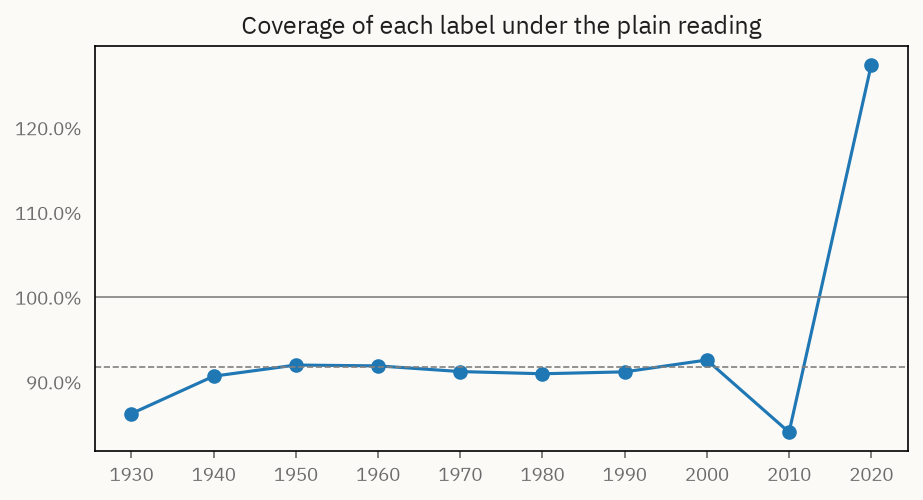

In [7]:
census_total = census_age_sex[census_age_sex["sex"] == "total"].copy()
census_total["decade"] = ((REFERENCE_YEAR - census_total["age"]) // 10 * 10).clip(
    FIRST_DECADE, LAST_DECADE
)

coverage = pd.DataFrame(
    {
        "listed_people": names_decade.groupby("decade")["count"].sum(),
        "census_people_plain": census_total.groupby("decade")["population"].sum(),
    }
).reset_index()
coverage["coverage_plain"] = coverage["listed_people"] / coverage["census_people_plain"]
display(coverage)

# If the 2010 and 2020 labels differ from the plain reading only in where they split,
# their pooled coverage should match the other labels'
overall = decade_people / population
youngest = coverage[coverage["decade"] >= 2010]
pooled = youngest["listed_people"].sum() / youngest["census_people_plain"].sum()
print(
    f"2010 and 2020 labels pooled: {pooled:.1%} (decade table overall: {overall:.1%})"
)

ax = coverage.plot(
    x="decade",
    y="coverage_plain",
    marker="o",
    legend=False,
    xticks=coverage["decade"],
    figsize=(7, 3.5),
    title="Coverage of each label under the plain reading",
)
ax.axhline(1, color="grey", linewidth=0.8)  # the ceiling a threshold cannot exceed
ax.axhline(overall, color="grey", linewidth=0.8, linestyle="--")  # decade table overall
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("")
plt.show()

The labels from 1940 to 2000 cover about what the decade table covers overall. The 2010 label falls short and the 2020 label exceeds 100%, which a threshold that only removes people cannot produce; pooled, the two cover what the middle labels do, so IBGE splits the youngest cohorts at an older age than the plain reading.

The oldest label is open at the other end. Everyone aged 93 or more on 1 August 2022 was born before 1930, yet the twenty most common names keep almost all of their national bearers across the ten labels, so those births must sit in the 1930 label.

In [8]:
in_decades = names_decade.groupby("name")["count"].sum()
most_common = names_total.head(GAP_CHECK_NAMES).set_index("name")["count"]
decade_gaps = pd.DataFrame(
    {
        "national": most_common,
        "in_decades": in_decades.reindex(most_common.index),
    }
)
decade_gaps["not_in_any_decade"] = decade_gaps["national"] - decade_gaps["in_decades"]

born_before_first_label_at_least = census_total.loc[
    census_total["age"] >= REFERENCE_YEAR - FIRST_DECADE + 1, "population"
].sum()
print(
    f"Residents aged {REFERENCE_YEAR - FIRST_DECADE + 1} or more: "
    f"{born_before_first_label_at_least:,}"
)
display(decade_gaps)

Residents aged 93 or more: 359,952


,national,in_decades,not_in_any_decade
name,,,
maria,12284478,12284474,4
jose,5164752,5164750,2
ana,3948650,3948644,6
joao,3430608,3430596,12
antonio,2241094,2241082,12
francisco,1665494,1665492,2
pedro,1624478,1624473,5
carlos,1474492,1474484,8
lucas,1341525,1341522,3


In [9]:
# Bearers no label accounts for, even allowing 19 for each label a name is missing from
national_totals = names_total.set_index("name")["count"]
missing_labels = len(decades) - names_decade.groupby("name").size().reindex(
    national_totals.index, fill_value=0
)
beyond_suppression = (
    national_totals
    - in_decades.reindex(national_totals.index, fill_value=0)
    - (DISCLOSURE_THRESHOLD - 1) * missing_labels
).clip(lower=0)
has_excess = beyond_suppression > 0
print(f"Bearers unaccounted for beyond suppression: {beyond_suppression.sum():,}")
print(f"Names with any: {has_excess.sum():,}")
print(
    f"Listed under all {len(decades)} labels: "
    f"{(has_excess & (missing_labels == 0)).sum():,}"
)

Bearers unaccounted for beyond suppression: 9,332
Names with any: 1,578
Listed under all 10 labels: 1,294


The labels from 1940 to 2000 cover about what the decade table covers overall. The 2010 label falls short and the 2020 label exceeds 100%, which a threshold that only removes people cannot produce; pooled, the two cover what the middle labels do, so IBGE splits the youngest cohorts at an older age than the plain reading.

The oldest label is open at the other end. Everyone aged 93 or more on 1 August 2022 was born before 1930, yet the twenty most common names keep almost all of their national bearers across the ten labels, so those births must sit in the 1930 label.

### 3.3 Sex classes

A name's sex class comes from its female and male counts, $f$ and $m$, in `names_sex` and its total $t$ in `names_total`. A name missing from one sex table has fewer than 20 bearers of that sex, and that count is taken as 0. The class is

$$\text{class} = \begin{cases} f & \text{if } f / t \ge 0.95 \\ m & \text{if } m / t \ge 0.95 \\ \text{other} & \text{otherwise.} \end{cases}$$

The class is national: a name keeps one class in every decade, even where its use shifted between the sexes. `sex_class_coverage` gives, for each decade, the listed people in each class as a share of all listed people of that decade.

sex_class
f        57508
m        45286
other    25664
Names in neither sex table (class other by construction): 4,725


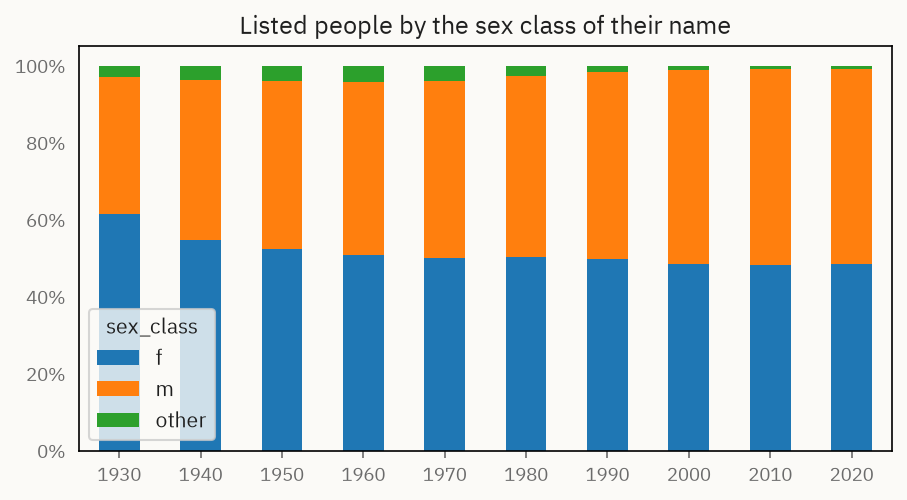

In [10]:
# Female and male counts per name, 0 where the name is missing from that sex's table
counts_by_sex = names_sex.pivot(index="name", columns="sex", values="count")
name_classes = (
    names_total.set_index("name")[["count"]]
    .join(counts_by_sex)
    .fillna(0)
    .astype("int64")
)
name_classes["sex_class"] = np.select(
    [
        name_classes["f"] / name_classes["count"] >= SEX_CLASS_THRESHOLD,
        name_classes["m"] / name_classes["count"] >= SEX_CLASS_THRESHOLD,
    ],
    ["f", "m"],
    default="other",
)

names_decade_classed = names_decade.join(name_classes["sex_class"], on="name")
sex_class_composition = (
    names_decade_classed.groupby(["decade", "sex_class"])["count"]
    .sum()
    .rename("listed_people")
    .reset_index()
)
sex_class_composition["share"] = sex_class_composition[
    "listed_people"
] / sex_class_composition.groupby("decade")["listed_people"].transform("sum")

in_neither = (name_classes["f"] == 0) & (name_classes["m"] == 0)
print(name_classes["sex_class"].value_counts().to_string())
print(f"Names in neither sex table (class other by construction): {in_neither.sum():,}")

# Each decade's listed people split by the class of their name
ax = sex_class_composition.pivot(
    index="decade", columns="sex_class", values="share"
).plot(
    kind="bar",
    stacked=True,
    rot=0,
    figsize=(7, 3.5),
    title="Listed people by the sex class of their name",
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("")
plt.show()

Class `other` is a small share of every decade, and the `f` share is highest in the oldest labels; section 4.2 returns to that imbalance.

### 3.4 Independent audit

A separate implementation in [`audit/`](audit/), written from IBGE's raw responses before its author read this notebook's code, recomputes twelve of the thirteen results tables (all but `life_cycle_robustness.csv`) and matches them: integers and rankings exactly, floats to rounding error. [`audit/AUDIT.md`](audit/AUDIT.md) reports the comparison and the audit's sensitivity checks.

## 4. How concentrated were first names in each birth decade?

For decade $d$, the listed people are $L_d = \sum_i c_{d,i}$ and the share of name $i$ is $p_{d,i} = c_{d,i} / L_d$. With the names in the ordering, $p_{(1)} \ge p_{(2)} \ge \dots$:

- the top-$k$ share is $\sum_{r=1}^{k} p_{(r)}$, for $k$ = 1, 10 and 100;
- $n_{50} = \min\left\{k : \sum_{r=1}^{k} p_{(r)} \ge 0.5\right\}$ is the number of names that together account for half of the listed people;
- the Hill numbers ${}^{1}D = \exp\left(-\sum_i p_i \ln p_i\right)$ and ${}^{2}D = 1 / \sum_i p_i^2$ are effective numbers of names: a decade in which $n$ names were equally common has ${}^{1}D = {}^{2}D = n$. ${}^{2}D$ is driven by the commonest names, ${}^{1}D$ weighs every name by its share.

The table leaves out names given to fewer than 20 people in a decade. They would add small shares, which ${}^{1}D$ counts more heavily than ${}^{2}D$, so ${}^{1}D$ is the more sensitive of the two to that threshold.

The set `without_heads` removes `maria`, `ana`, `joao` and `jose` and recomputes $L_d$ and every share without them.

In [11]:
def concentration(counts: pd.Series) -> dict[str, object]:
    """Concentration measures of one distribution of bearers over names.

    ``counts`` is indexed by name and ordered by count descending, then name.
    """
    people = int(counts.sum())
    shares = counts / people
    cumulative_people = counts.cumsum()
    return {
        "listed_people": people,
        "listed_names": len(counts),
        "top1_name": counts.index[0],
        **{f"top{k}_share": float(counts.iloc[:k].sum() / people) for k in TOP_K},
        # Doubling the integer counts keeps the comparison exact.
        "n50": int((2 * cumulative_people < people).sum()) + 1,
        "hill_q1": float(np.exp(entropy(counts))),
        "hill_q2": float(1 / (shares**2).sum()),
    }


keys = ["decade", "subset"]
ranked_names = pd.concat(
    [
        names_decade.assign(subset="all"),
        names_decade[~names_decade["name"].isin(LEADING_NAMES)].assign(
            subset="without_leading_names"
        ),
    ],
    ignore_index=True,
).sort_values(
    ["decade", "subset", "count", "name"], ascending=[True, True, False, True]
)

concentration_by_decade = pd.DataFrame(
    [
        {
            "decade": decade,
            "subset": subset,
            **concentration(group.set_index("name")["count"]),
        }
        for (decade, subset), group in ranked_names.groupby(keys, sort=True)
    ]
).astype({"decade": "int16", "top1_name": "string"})
display(concentration_by_decade)

,decade,subset,listed_people,listed_names,top1_name,top1_share,top10_share,top100_share,n50,hill_q1,hill_q2
0,1930,all,2539832,5965,maria,0.167515,0.334267,0.582318,52,378.654919,29.580753
1,1930,without_leading_names,1892314,5961,antonio,0.034606,0.147242,0.446052,139,969.732994,239.173302
2,1940,all,6840789,11959,maria,0.163888,0.342232,0.579125,52,426.345598,29.543975
3,1940,without_leading_names,5056678,11955,antonio,0.040744,0.150841,0.437130,149,1173.224361,223.501238
4,1950,all,14145527,18557,maria,0.159869,0.339661,0.580336,52,442.453753,30.561053
5,1950,without_leading_names,10491103,18553,antonio,0.038816,0.147645,0.440920,143,1208.206587,227.602202
6,1960,all,20796151,25887,maria,0.118272,0.280378,0.526924,83,668.997562,51.027135
7,1960,without_leading_names,16548108,25883,antonio,0.028871,0.125086,0.412505,163,1431.849775,295.475017
8,1970,all,24951988,32071,maria,0.064624,0.191123,0.472421,118,1054.346115,127.799354
9,1970,without_leading_names,21797546,32067,antonio,0.017951,0.107143,0.403806,169,1579.615193,376.946120


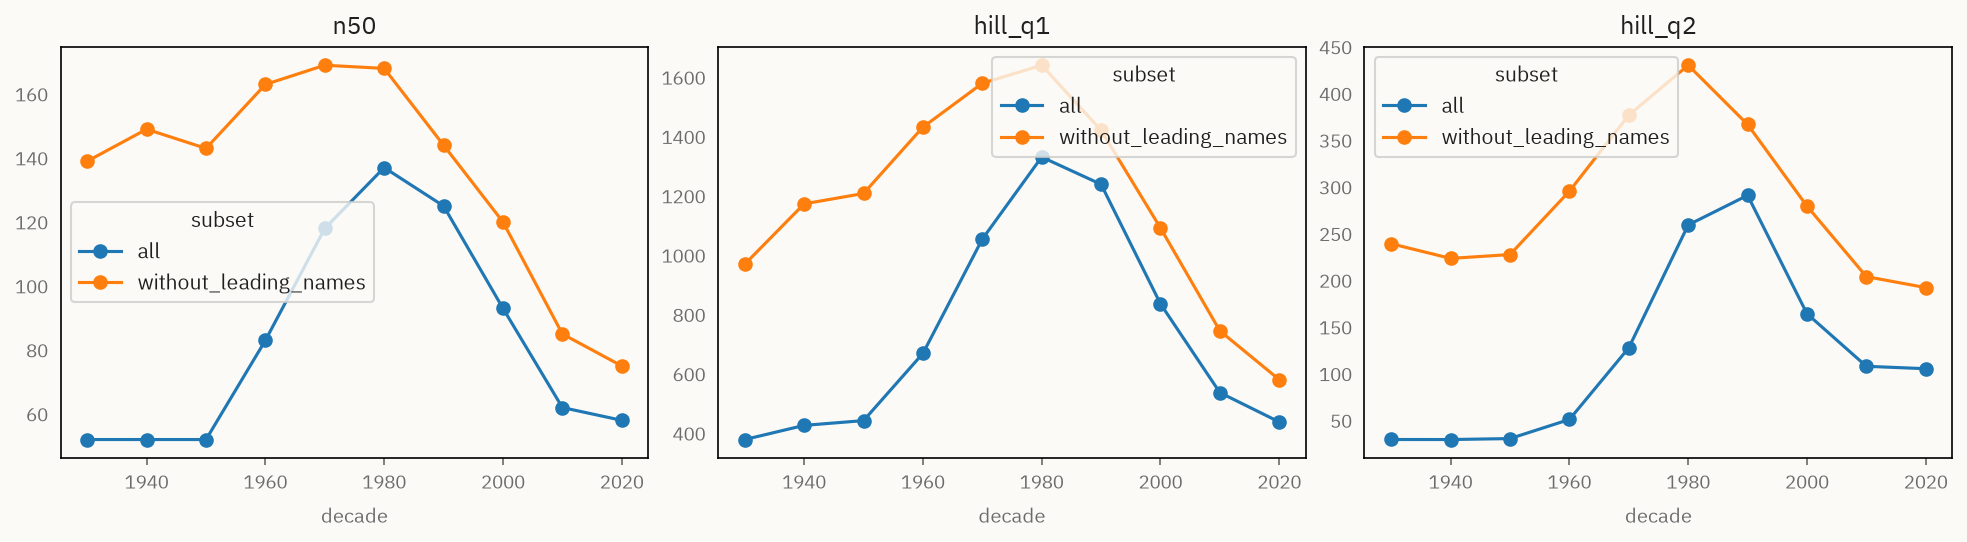

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for ax, measure in zip(axes, ["n50", "hill_q1", "hill_q2"], strict=True):
    concentration_by_decade.pivot(
        index="decade", columns="subset", values=measure
    ).plot(ax=ax, marker="o", title=measure)
plt.show()

With every name counted, half of the listed people of 1930, 1940 and 1950 bear one of 52 names, and `maria` alone accounts for 16% to 17% of them. Concentration then falls: $n_{50}$ reaches 137 in 1980 and ${}^{2}D$ reaches 291 in 1990. It rises again from 2000, to $n_{50} = 58$ and ${}^{2}D = 105$ in 2020.

Without the four heads, the oldest decades are far less concentrated (${}^{2}D$ is 239 in 1930, against 30 with them), and $n_{50}$ stays between 139 and 169 from 1930 to 1980. The rise after 1990 remains: without the heads, $n_{50}$ is 85 in 2010 and 75 in 2020. Once the heads are removed, `antonio` leads every decade from 1930 to 1980, `lucas` leads 1990, `gabriel` 2000, and `davi` 2010 and 2020. Compound names that start with other common first words (Davi Lucca, Pedro Henrique, Enzo Gabriel) are also collapsed onto their first word, so part of the renewed concentration after 1990 may come from how IBGE records names, not only from parents' choices. IBGE counts spelling variants separately (Sophia and Sofia, Matheus and Mateus), which pulls in the other direction; counted by sound, concentration after 1990 would be higher.

The disclosure threshold is a fixed count, so it cuts a larger share of a small decade: 20 people are $7.9 \times 10^{-6}$ of the listed people of 1930 and $6.8 \times 10^{-7}$ of those of 1980. `listed_names` and ${}^{1}D$ therefore lose more of their tail in 1930, 1940 and 2020 than in the large decades; $n_{50}$, the top shares and ${}^{2}D$ rest mainly on the common names. Section 4.1 applies one cut-off to every decade.

The renewed concentration holds in the 2010 label as well as in the 2020 label, whose span of birth years is unknown (section 3.2): $n_{50}$ is 137 in 1980, 62 in 2010 and 58 in 2020, and without the heads 168, 85 and 75.

### 4.1 Robustness: one cut-off for every decade

The threshold of 20 people is a different share of each decade, $20 / L_d$. The largest of these shares belongs to the 1930 label, the smallest:

$$s^{*} = \max_d \frac{20}{L_d}.$$

Applying $s^{*}$ to every decade keeps the names with $p_{d,i} \ge s^{*}$, so every decade loses its tail at the same share. `share_kept` is the share of the decade's listed people that the kept names hold. Their shares are renormalised to sum to 1,

$$q_{d,i} = \frac{c_{d,i}}{\sum_{j \text{ kept}} c_{d,j}},$$

and ${}^{1}D$ and ${}^{2}D$ are recomputed from $q_{d,i}$ as in section 4.

In [13]:
cutoff = (DISCLOSURE_THRESHOLD / listed_people).max()
names_above_cutoff = names_decade[
    names_decade["count"] / names_decade["decade"].map(listed_people) >= cutoff
]

concentration_common_cutoff = (
    pd.DataFrame(
        [
            {
                "decade": decade,
                "cutoff": cutoff,
                **concentration(group.set_index("name")["count"]),
            }
            for decade, group in names_above_cutoff.groupby("decade", sort=True)
        ]
    )
    .astype({"decade": "int16"})
    .rename(columns={"listed_names": "names_kept"})
)
concentration_common_cutoff["share_kept"] = concentration_common_cutoff[
    "listed_people"
] / concentration_common_cutoff["decade"].map(listed_people)
concentration_common_cutoff = concentration_common_cutoff[
    ["decade", "cutoff", "names_kept", "share_kept", "hill_q1", "hill_q2"]
]
print(
    f"Common cut-off: {cutoff:.4g}, the share of {DISCLOSURE_THRESHOLD} people "
    f"in the {listed_people.idxmin()} label"
)
display(concentration_common_cutoff)

# Side by side with the fixed threshold of section 4
display(
    concentration_common_cutoff[["decade", "hill_q1", "hill_q2"]].merge(
        concentration_by_decade.loc[
            concentration_by_decade["subset"] == "all",
            ["decade", "hill_q1", "hill_q2"],
        ],
        on="decade",
        suffixes=("_common_cutoff", "_fixed_threshold"),
    )
)

Common cut-off: 7.875e-06, the share of 20 people in the 1930 label


,decade,cutoff,names_kept,share_kept,hill_q1,hill_q2
0,1930,0.000008,5965,1.000000,378.654919,29.580753
1,1940,0.000008,5843,0.971665,345.896454,27.893554
2,1950,0.000008,5416,0.958844,321.583265,28.097428
3,1960,0.000008,5752,0.949328,456.124261,45.987272
4,1970,0.000008,6147,0.941633,691.921436,113.319124
5,1980,0.000008,6293,0.936393,848.924791,227.382015
6,1990,0.000008,6080,0.940638,812.473900,257.524746
7,2000,0.000008,5198,0.951892,585.399139,148.847274
8,2010,0.000008,4284,0.965327,411.049091,100.607102
9,2020,0.000008,3854,0.979554,376.221579,101.118793


,decade,hill_q1_common_cutoff,hill_q2_common_cutoff,hill_q1_fixed_threshold,hill_q2_fixed_threshold
0,1930,378.654919,29.580753,378.654919,29.580753
1,1940,345.896454,27.893554,426.345598,29.543975
2,1950,321.583265,28.097428,442.453753,30.561053
3,1960,456.124261,45.987272,668.997562,51.027135
4,1970,691.921436,113.319124,1054.346115,127.799354
5,1980,848.924791,227.382015,1331.044558,259.308113
6,1990,812.473900,257.524746,1239.085471,291.037848
7,2000,585.399139,148.847274,836.160083,164.268514
8,2010,411.049091,100.607102,536.857169,107.962865
9,2020,376.221579,101.118793,437.849415,105.383030


In [14]:
concentration_without_top = (
    pd.DataFrame(
        [
            {
                "decade": decade,
                **concentration(
                    group.sort_values(["count", "name"], ascending=[False, True])
                    .iloc[TOP_REMOVED:]
                    .set_index("name")["count"]
                ),
            }
            for decade, group in names_decade.groupby("decade", sort=True)
        ]
    )
    .astype({"decade": "int16", "top1_name": "string"})
    .rename(columns={"top1_name": "first_kept_name"})[
        [
            "decade",
            "first_kept_name",
            "listed_people",
            "listed_names",
            "n50",
            "hill_q1",
            "hill_q2",
        ]
    ]
)
display(concentration_without_top)

,decade,first_kept_name,listed_people,listed_names,n50,hill_q1,hill_q2
0,1930,luzia,1527089,5945,230,1448.886515,563.550910
1,1940,rosa,4074369,11939,258,1865.291082,620.907247
2,1950,geraldo,8464423,18537,237,1920.168588,594.243231
3,1960,jorge,13804298,25867,242,2095.408704,630.142500
4,1970,fabio,18599207,32051,236,2152.979555,629.069416
5,1980,vanessa,23872111,37361,219,2068.333528,577.319667
6,1990,antonio,22782416,34551,191,1834.899625,515.152396
7,2000,rafael,19953845,27354,172,1525.625735,463.214986
8,2010,carlos,15719896,18754,129,1100.500212,366.345192
9,2020,nicolas,6273048,8965,108,827.799481,321.962784


In [15]:
# Two extreme allocations of the unlisted census residents: 19 per name, or singletons
max_unlisted = DISCLOSURE_THRESHOLD - 1
unlisted_by_decade = coverage.set_index("decade").eval(
    "census_people_plain - listed_people"
)
unlisted_rows = []
for decade in UNLISTED_DECADES:
    counts = names_decade.loc[names_decade["decade"] == decade, "count"].to_numpy()
    unlisted = int(unlisted_by_decade.loc[decade])
    full_groups, remainder = divmod(unlisted, max_unlisted)
    tail = [
        np.full(full_groups, max_unlisted, dtype=np.int64),
        *([np.array([remainder], dtype=np.int64)] if remainder else []),
    ]
    assumptions = {
        "names_of_19": np.concatenate([counts, *tail]),
        "singletons": np.concatenate([counts, np.ones(unlisted, dtype=np.int64)]),
    }
    for unlisted_as, extended in assumptions.items():
        shares = extended / extended.sum()
        unlisted_rows.append(
            {
                "decade": decade,
                "unlisted_as": unlisted_as,
                "unlisted_people": unlisted,
                "hill_q1": float(np.exp(entropy(extended))),
                "hill_q2": float(1 / (shares**2).sum()),
            }
        )

concentration_with_unlisted = pd.DataFrame(unlisted_rows).astype({"decade": "int16"})
display(concentration_with_unlisted)

listed_only = (
    concentration_by_decade.loc[
        (concentration_by_decade["subset"] == "all")
        & concentration_by_decade["decade"].isin(UNLISTED_DECADES),
        ["decade", "hill_q1", "hill_q2"],
    ]
    .set_index("decade")
    .sort_index()
)
for unlisted_as, group in concentration_with_unlisted.groupby("unlisted_as", sort=True):
    adjusted = group.set_index("decade")[["hill_q1", "hill_q2"]].sort_index()
    for measure in ("hill_q1", "hill_q2"):
        base_step = listed_only[measure].diff()
        adj_step = adjusted[measure].diff()
        reversals = adj_step.index[
            (np.sign(base_step) != np.sign(adj_step)) & base_step.notna()
        ]
        for decade in reversals:
            previous = int(listed_only.index[listed_only.index.get_loc(decade) - 1])
            print(
                f"Reversal ({unlisted_as}, {measure}): {previous}->{decade} "
                f"listed {listed_only.loc[previous, measure]:.2f}->{listed_only.loc[decade, measure]:.2f}, "
                f"with unlisted {adjusted.loc[previous, measure]:.2f}->{adjusted.loc[decade, measure]:.2f}"
            )

,decade,unlisted_as,unlisted_people,hill_q1,hill_q2
0,1940,names_of_19,702206,880.333442,35.920347
1,1940,singletons,702206,1157.952812,35.920633
2,1950,names_of_19,1229279,870.944006,36.103374
3,1950,singletons,1229279,1102.127383,36.103496
4,1960,names_of_19,1831484,1324.971675,60.410413
5,1960,singletons,1831484,1681.547177,60.410648
6,1970,names_of_19,2397294,2158.478735,153.534561
7,1970,singletons,2397294,2794.064764,153.535921
8,1980,names_of_19,2939527,2768.285601,313.298834
9,1980,singletons,2939527,3610.857163,313.303729


Reversal (names_of_19, hill_q1): 1940->1950 listed 426.35->442.45, with unlisted 880.33->870.94
Reversal (singletons, hill_q1): 1940->1950 listed 426.35->442.45, with unlisted 1157.95->1102.13


The direction of change matches section 4 from 1950 to 2020 for ${}^{1}D$ and from 1930 to 2010 for ${}^{2}D$, but between 1930 and 1950 ${}^{1}D$ falls under one cut-off (379, 346, 322) where it rises under the fixed threshold (379, 426, 442). Under the common cut-off, ${}^{2}D$ (`hill_q2`) also rises slightly from 2010 to 2020 (100.6 to 101.1), so the 2020 label is not part of the claimed direction.

### 4.2 Robustness: concentration within women's and men's names

The older labels list more women than men: the `f` class holds 61.6% of the listed people of 1930 and about 48% from 2000 on (section 3.3), so a change from one label to the next could reflect the mix of the sexes rather than the names given within each. The measures of section 4 are therefore recomputed within each sex class $s$ of section 3.3, `f` and `m` (`other` is left out). The denominator is $L_{d,s}$, the listed people of decade $d$ in class $s$:

$$L_{d,s} = \sum_{i \in s} c_{d,i}, \qquad p_{d,s,i} = \frac{c_{d,i}}{L_{d,s}},$$

and the names of each decade and class are taken in the ordering.

In [16]:
class_keys = ["decade", "sex_class"]
ranked_by_class = names_decade_classed[
    names_decade_classed["sex_class"].isin(["f", "m"])
].sort_values(
    ["decade", "sex_class", "count", "name"], ascending=[True, True, False, True]
)
ranked_by_class["listed_people"] = ranked_by_class.groupby(class_keys)[
    "count"
].transform("sum")
ranked_by_class["share"] = ranked_by_class["count"] / ranked_by_class["listed_people"]
ranked_by_class["rank"] = ranked_by_class.groupby(class_keys).cumcount() + 1

concentration_by_class = pd.DataFrame(
    [
        {
            "decade": decade,
            "sex_class": sex_class,
            **concentration(group.set_index("name")["count"]),
        }
        for (decade, sex_class), group in ranked_by_class.groupby(class_keys, sort=True)
    ]
).astype({"decade": "int16", "top1_name": "string"})[
    [
        "decade",
        "sex_class",
        "listed_people",
        "listed_names",
        "top1_name",
        "top1_share",
        "top10_share",
        "n50",
        "hill_q2",
    ]
]
display(
    concentration_by_class.pivot(
        index="decade", columns="sex_class", values=["n50", "top10_share", "hill_q2"]
    )
)

n50       top10_share               hill_q2            
sex_class     f     m           f         m           f           m
decade                                                             
1930       30.0  16.0    0.389289  0.448926   13.009736   26.996843
1940       27.0  18.0    0.410332  0.430492   10.815112   27.794711
1950       25.0  20.0    0.413032  0.416007   10.410350   29.759309
1960       40.0  31.0    0.342186  0.356470   17.554190   41.513415
1970       61.0  45.0    0.263651  0.264923   48.475002   80.271704
1980       80.0  51.0    0.192338  0.200255  119.062574  128.236348
1990       77.0  47.0    0.186601  0.197287  151.364060  130.766087
2000       63.0  34.0    0.248829  0.262512   73.977938   87.082170
2010       37.0  27.0    0.315364  0.310875   42.913914   67.685628
2020       29.0  28.0    0.334412  0.303884   39.188307   72.889641

Within each sex class, concentration falls from the 1950 label to the 1980 label and rises again after it, as with every name counted. Half of the people with `f` names share 25 names in 1950, 80 in 1980 and 29 in 2020; half of those with `m` names share 20, 51 and 28. Between 1930 and 1950 the classes move apart: concentration rises slightly in `f` ($n_{50}$ from 30 to 25) and falls slightly in `m` (16 to 20). ${}^{2}D$ follows the same path, from 10 (`f`) and 30 (`m`) in 1950 to 119 and 128 in 1980, and 39 and 73 in 2020. The fall and rise of concentration in section 4 therefore does not come from the changing share of women among the listed people.

$n_{50}$ is higher for `f` than for `m` in every label, while ${}^{2}D$, driven by the commonest names, is lower for `f` in every label but 1990, because `maria` alone holds a large share of the `f` names (section 6.1).

### 4.3 The ten most common names within each sex class

The figure takes the first ten names of each decade and sex class from the ranking in section 4.2, ordered by count descending and then name ascending. Each share uses all listed people of that decade and sex class as its denominator.

In [17]:
top_names_by_class = (
    ranked_by_class.loc[
        ranked_by_class["rank"] <= NAMES_PER_DECADE,
        ["decade", "sex_class", "rank", "name", "count", "share"],
    ]
    .rename(columns={"count": "bearers", "share": "share_within_class"})
    .reset_index(drop=True)
)

## 5. Names that mark a generation

A name marks decade $d$ when its share there is high compared with the other nine decades pooled. With $c_{\neg d,i}$ and $L_{\neg d}$ summed over the other decades, Hardie's Log Ratio is

$$p_{\neg d,i} = \frac{c_{\neg d,i} + 0.5}{L_{\neg d} + 0.5}, \qquad \text{LR}_{d,i} = \log_2 \frac{p_{d,i}}{p_{\neg d,i}}.$$

Each unit of LR doubles the ratio: a name with LR = 3 is eight times as common, relative to the listed people, in decade $d$ as in the others. The 0.5 keeps the ratio finite for names listed in one decade only. Only names held by at least 1 in 2,000 listed people of the decade qualify, so the list is not led by rare names; the 20 with the highest LR are kept, ties going to the larger count.

In [18]:
decade_shares = names_decade.assign(
    listed_people=names_decade["decade"].map(listed_people),
    # The name's count over the other nine decades, 0 where it is listed in this decade only
    count_elsewhere=names_decade.groupby("name")["count"].transform("sum")
    - names_decade["count"],
)
decade_shares["listed_elsewhere"] = listed_people.sum() - decade_shares["listed_people"]
decade_shares["share_in_decade"] = (
    decade_shares["count"] / decade_shares["listed_people"]
)
decade_shares["share_elsewhere"] = (decade_shares["count_elsewhere"] + SMOOTHING) / (
    decade_shares["listed_elsewhere"] + SMOOTHING
)
decade_shares["log_ratio"] = np.log2(
    decade_shares["share_in_decade"] / decade_shares["share_elsewhere"]
)

distinctive = (
    decade_shares[decade_shares["share_in_decade"] >= DISTINCTIVE_MIN_SHARE]
    .sort_values(
        ["decade", "log_ratio", "count", "name"], ascending=[True, False, False, True]
    )
    .groupby("decade")
    .head(DISTINCTIVE_TOP)
)
distinctive["rank"] = distinctive.groupby("decade").cumcount() + 1
distinctive = distinctive.rename(columns={"count": "bearers"})[
    [
        "decade",
        "name",
        "bearers",
        "share_in_decade",
        "share_elsewhere",
        "log_ratio",
        "rank",
    ]
].reset_index(drop=True)

preview = distinctive[distinctive["rank"] <= SHOWN_PER_DECADE]
display(preview.pivot(index="rank", columns="decade", values="name"))
display(preview.pivot(index="rank", columns="decade", values="log_ratio"))

decade,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
rank,,,,,,,,,,
1,therezinha,mercedes,creusa,amarildo,valdirene,eder,jessica,kailane,sophia,gael
2,thereza,alzira,cleuza,tania,andrea,lidiane,gessica,camile,sofia,ravi
3,edith,leonor,neusa,salete,sandro,tatiane,romario,cauan,enzo,noa
4,julieta,irma,teresinha,margarete,adriana,tatiana,mayara,caua,valentina,noah
5,yolanda,elvira,neuza,fatima,vanusa,michelle,dayane,vitoria,emanuelly,zoe


decade,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
rank,,,,,,,,,,
1,5.755881,3.441641,2.605383,3.056055,2.793151,2.738297,3.899781,4.217704,3.835117,6.996438
2,5.357584,3.167656,2.553915,2.391257,2.707884,2.647888,3.771974,3.163799,3.549702,6.591994
3,4.540941,3.127945,2.536612,2.291748,2.299933,2.506494,3.290642,2.841803,3.499858,6.556701
4,4.099615,3.101224,2.534345,2.281143,2.288701,2.487407,2.690036,2.779411,3.330010,6.230530
5,4.081117,3.086919,2.509225,2.165630,2.255650,2.465640,2.655499,2.678662,3.302682,6.126641


In [19]:
# Upper bound on suppression's effect: put every unlisted bearer in the reference
unlisted_bearers = distinctive["name"].map(national_totals - in_decades)
count_elsewhere = distinctive["name"].map(in_decades) - distinctive["bearers"]
listed_elsewhere = listed_people.sum() - distinctive["decade"].map(listed_people)
adjusted_share_elsewhere = (count_elsewhere + unlisted_bearers + SMOOTHING) / (
    listed_elsewhere + unlisted_bearers + SMOOTHING
)
adjusted_log_ratio = np.log2(distinctive["share_in_decade"] / adjusted_share_elsewhere)
print(
    f"Largest Log Ratio drop: "
    f"{(distinctive['log_ratio'] - adjusted_log_ratio).max():.3f}"
)

reranked_top = (
    distinctive.assign(adjusted_log_ratio=adjusted_log_ratio)
    .sort_values(
        ["decade", "adjusted_log_ratio", "bearers", "name"],
        ascending=[True, False, False, True],
    )
    .groupby("decade")
    .head(SHOWN_PER_DECADE)
)
reranked_top["new_rank"] = reranked_top.groupby("decade").cumcount() + 1
top_changes = preview.merge(
    reranked_top[["decade", "new_rank", "name"]],
    left_on=["decade", "rank"],
    right_on=["decade", "new_rank"],
    suffixes=("_published", "_adjusted"),
)
print(
    top_changes[top_changes["name_published"] != top_changes["name_adjusted"]][
        ["decade", "rank", "name_published", "name_adjusted"]
    ].to_string(index=False)
)

Largest Log Ratio drop: 0.037
 decade  rank name_published name_adjusted
   1990     5         dayane        maiara


In [20]:
floor_frames = []
for min_share in DISTINCTIVE_FLOOR_CHECKS:
    top_names = (
        decade_shares[decade_shares["share_in_decade"] >= min_share]
        .sort_values(
            ["decade", "log_ratio", "count", "name"],
            ascending=[True, False, False, True],
        )
        .groupby("decade")
        .head(SHOWN_PER_DECADE)
        .copy()
    )
    top_names["rank"] = top_names.groupby("decade").cumcount() + 1
    top_names["min_share"] = min_share
    floor_frames.append(top_names[["min_share", "decade", "rank", "name", "log_ratio"]])

distinctive_floor_check = pd.concat(floor_frames, ignore_index=True)

base_top = (
    distinctive_floor_check[
        distinctive_floor_check["min_share"] == DISTINCTIVE_MIN_SHARE
    ]
    .groupby("decade")["name"]
    .apply(set)
)
for min_share in DISTINCTIVE_FLOOR_CHECKS:
    if min_share == DISTINCTIVE_MIN_SHARE:
        continue
    alt_top = (
        distinctive_floor_check[distinctive_floor_check["min_share"] == min_share]
        .groupby("decade")["name"]
        .apply(set)
    )
    entered = sum(len(alt_top[decade] - base_top[decade]) for decade in decades)
    print(f"min_share={min_share}: {entered} names enter the top {SHOWN_PER_DECADE}")

min_share=0.0002: 27 names enter the top 5
min_share=0.001: 17 names enter the top 5


In [21]:
# Equal-weight reference across the other nine labels, to separate cohort size from peaks
decade_share_matrix = decade_shares.pivot(
    index="name", columns="decade", values="share_in_decade"
).fillna(0.0)
other_count = len(decades) - 1
mean_listed = listed_people.mean()

averaged_frames = []
for decade in decades:
    other_decades = [other for other in decades if other != decade]
    reference_share = (
        decade_share_matrix[other_decades].sum(axis="columns") + SMOOTHING / mean_listed
    ) / other_count
    eligible = decade_shares[
        (decade_shares["decade"] == decade)
        & (decade_shares["share_in_decade"] >= DISTINCTIVE_MIN_SHARE)
    ].copy()
    eligible["log_ratio"] = np.log2(
        eligible["share_in_decade"] / eligible["name"].map(reference_share)
    )
    top_averaged = (
        eligible.sort_values(
            ["log_ratio", "count", "name"], ascending=[False, False, True]
        )
        .head(DISTINCTIVE_TOP)
        .copy()
    )
    top_averaged["rank"] = np.arange(1, len(top_averaged) + 1)
    top_averaged["reference"] = "averaged"
    averaged_frames.append(
        top_averaged[["decade", "reference", "rank", "name", "log_ratio"]]
    )

pooled_reference = distinctive[["decade", "rank", "name", "log_ratio"]].assign(
    reference="pooled"
)[["decade", "reference", "rank", "name", "log_ratio"]]
distinctive_reference_check = pd.concat(
    [pooled_reference, *averaged_frames], ignore_index=True
).sort_values(["decade", "reference", "rank"], ignore_index=True)

leaders = distinctive_reference_check[distinctive_reference_check["rank"] == 1].pivot(
    index="decade", columns="reference", values=["name", "log_ratio"]
)
print(leaders.to_string())

                 name             log_ratio          
reference    averaged      pooled  averaged    pooled
decade                                               
1930       therezinha  therezinha  4.718383  5.755881
1940            darci    mercedes  2.173618  3.441641
1950           cleuza      creusa  2.262552  2.605383
1960         amarildo    amarildo  3.536157  3.056055
1970        valdirene   valdirene  3.366527  2.793151
1980          lidiane        eder  3.268189  2.738297
1990          jessica     jessica  4.483489  3.899781
2000          kailane     kailane  4.347851  4.217704
2010           sophia      sophia  3.230389  3.835117
2020             gael        gael   7.24353  6.996438


The most distinctive names of 1930 (`therezinha`, `thereza`, `edith`, `julieta`, `yolanda`) have Log Ratios between 4.1 and 5.8, so each is between about 17 and 54 times as common, relative to the listed people, as in the other decades pooled. The lists of 1950 to 1980 are the flattest: their leaders score between 2.6 and 3.1 and their twentieth names between 1.9 and 2.3. The 2020 label has the most distinctive list, led by `gael` (7.0, about 128 times) with `ravi`, `noa`, `noah` and `zoe`, and all of its twenty names score at least 4.88.

Spelling variants appear as separate names because IBGE counts them separately: `jessica` and `gessica` are the two most distinctive names of 1990, `cauan` and `caua` both reach the top five of 2000, `sophia` and `sofia` that of 2010, and `noa` and `noah` that of 2020.

### 5.1 Names for the generation figure

`generation_names.csv` uses the same minimum share and Log Ratio ordering as `distinctive_names.csv`, with one additional condition: a name's share must peak in the decade it represents. Ties in peak share go to the earlier decade. The figure draws each name's trajectory, so a name chosen to mark a decade should peak in it. The count of bearers comes from the national table. The share born at the peak uses the sum of the name's listed decade counts, so its numerator and denominator cover the same set of decades.

In [22]:
shares_by_name = decade_shares.pivot(
    index="name", columns="decade", values="share_in_decade"
).fillna(0)
peak_distinctive_names = decade_shares.assign(
    peak_decade=decade_shares["name"].map(shares_by_name.idxmax(axis="columns")),
    sex_class=decade_shares["name"].map(name_classes["sex_class"]),
    bearers_national=decade_shares["name"].map(name_classes["count"]),
    share_born_at_peak=decade_shares["count"]
    / (decade_shares["count"] + decade_shares["count_elsewhere"]),
)
peak_distinctive_names = (
    peak_distinctive_names[
        (peak_distinctive_names["decade"] == peak_distinctive_names["peak_decade"])
        & (peak_distinctive_names["share_in_decade"] >= DISTINCTIVE_MIN_SHARE)
    ]
    .sort_values(
        ["decade", "log_ratio", "count", "name"], ascending=[True, False, False, True]
    )
    .groupby("decade")
    .head(NAMES_PER_GENERATION)
)
peak_distinctive_names["rank"] = peak_distinctive_names.groupby("decade").cumcount() + 1
peak_distinctive_names = peak_distinctive_names.rename(
    columns={"count": "bearers_in_decade"}
)[
    [
        "decade",
        "rank",
        "name",
        "bearers_in_decade",
        "share_in_decade",
        "log_ratio",
        "peak_decade",
        "sex_class",
        "bearers_national",
        "share_born_at_peak",
    ]
].reset_index(drop=True)

## 6. Maria, Ana, João and José

The four most common names in the national table, as shares of the listed people of each decade, $p_{d,i} = c_{d,i} / L_d$.

IBGE counts only the first word of the name field ([technical note 01/2025](https://censo2022.ibge.gov.br/nomes/nota_tecnica/notatecnica.pdf)), so a Maria Eduarda is counted as `maria`. A rise in the share of a head name therefore cannot be separated, in these data, from a rise in compound names that begin with it.

In [23]:
leading_shares = names_decade[names_decade["name"].isin(LEADING_NAMES)].copy()
leading_shares["share"] = leading_shares["count"] / leading_shares["decade"].map(
    listed_people
)
leading_shares = leading_shares.rename(columns={"count": "bearers"})[
    ["decade", "name", "bearers", "share"]
].sort_values(["decade", "name"], ignore_index=True)

`maria` falls from 16.8% of the listed people of 1930 to 2.0% in 1990, then rises to 6.2% in 2020. `jose` peaks at 6.4% in 1950 and falls to about 1% from 2000 on, without a comparable rise. `joao` falls from 2.4% in 1940 to 0.9% in 1980 and returns to 3.1% in 2010. `ana` stays between 1.1% and 1.2% until 1950, rises to 1.8% in 1990 and 3.9% in 2010, and is at 3.0% in 2020. Older decades are mostly women among survivors, so shares among all listed people mix naming with mortality; section 6.1's shares within each sex class are the ones to read (`maria` rose from 27.2% to 30.6% of women's names between the 1930 and 1950 labels).

These data cannot tell how much of the rise of `maria`, `ana` and `joao` after 1990 comes from compound names such as Maria Eduarda, Ana Clara or João Pedro, since only the first word is counted.

### 6.1 The four heads within their sex class

`maria` and `ana` are in class `f`, `joao` and `jose` in class `m` (section 3.3). Each head's share of the listed people of its own class, $c_{d,i} / L_{d,s}$ with $L_{d,s}$ from section 4.2, takes the changing mix of the sexes out of the shares above.

In [24]:
# Each leading name's count over the listed people of its own sex class in the decade
leading_names_by_class = ranked_by_class.loc[
    ranked_by_class["name"].isin(LEADING_NAMES),
    ["decade", "name", "sex_class", "count", "listed_people"],
]
leading_names_by_class["share_within_class"] = (
    leading_names_by_class["count"] / leading_names_by_class["listed_people"]
)
leading_names_by_class = (
    leading_names_by_class.drop(columns="listed_people")
    .rename(columns={"count": "bearers"})
    .sort_values(["decade", "name"], ignore_index=True)
)
display(
    leading_names_by_class.pivot(
        index="decade", columns="name", values="share_within_class"
    )
)

name,ana,joao,jose,maria
decade,,,,
1930,0.019081,0.065831,0.147829,0.272019
1940,0.020074,0.057503,0.149608,0.299736
1950,0.022143,0.052496,0.145923,0.305710
1960,0.026265,0.040805,0.121200,0.232459
1970,0.032061,0.022194,0.077217,0.128926
1980,0.034168,0.018120,0.045102,0.064978
1990,0.035592,0.023257,0.029342,0.040228
2000,0.062932,0.052142,0.022501,0.079595
2010,0.080379,0.061528,0.019988,0.113526


Within their class, `maria` holds 27.2% of the people with `f` names in 1930 and 30.6% in 1950, falls to 4.0% in 1990 and returns to 12.7% in 2020. `ana` rises in every label from 1.9% in 1930 to 8.0% in 2010, then falls to 6.2% in 2020. `joao` falls from 6.6% of the people with `m` names in 1930 to 1.8% in 1980, and returns to 6.2% in 2010 and 5.3% in 2020. `jose` holds about 15% of them from 1930 to 1950 and between 2.0% and 2.5% from 2000 on.

## 7. Spelling

Five spelling patterns are matched with `re.search` on IBGE's form of each name (lower case, no diacritics); `any` matches a name with at least one of them.

| Pattern | Regular expression | Examples |
| --- | --- | --- |
| `kwy` | `[kwy]` | Kauã, Wesley, Yasmin |
| `th` | `th` | Thiago, Matheus, Arthur |
| `double_consonant` | `(bb\|dd\|ff\|gg\|ll\|mm\|nn\|pp\|tt\|zz)` | Allana, Emmanuel, Giovanna |
| `son_ending` | `son$` | Anderson, Emerson |
| `ton_ending` | `ton$` | Wellington, Milton |

For each decade and sex class (`all`, `f`, `m`), the share is the number of listed people whose name matches over all listed people of that decade and class:

$$s_{d,k} = \frac{\sum_{i \in k,\ i \text{ matches}} c_{d,i}}{\sum_{i \in k} c_{d,i}}.$$

In [25]:
pattern_flags = pd.DataFrame(
    {
        pattern: names_total["name"].str.contains(regex).astype(bool)
        for pattern, regex in SPELLING_PATTERNS.items()
    }
)
pattern_flags["any_feature"] = pattern_flags.any(axis="columns")
flag_columns = list(pattern_flags.columns)

decade_flags = names_decade_classed[["decade", "name", "sex_class", "count"]].join(
    pattern_flags.set_axis(names_total["name"]), on="name"
)
spelling_frames = []
for sex_class, subset in [
    ("all", decade_flags),
    *decade_flags[decade_flags["sex_class"].isin(["f", "m"])].groupby("sex_class"),
]:
    listed = subset.groupby("decade")["count"].sum()
    listed_names = subset.groupby("decade").size()
    people = (
        subset[flag_columns]
        .multiply(subset["count"], axis="index")
        .groupby(subset["decade"])
        .sum()
    )
    names = subset.groupby("decade")[flag_columns].sum()
    shares = people.div(listed, axis="index")
    type_shares = names.div(listed_names, axis="index")
    class_table = (
        pd.DataFrame(
            {
                "matching_people": people.stack(),
                "share": shares.stack(),
                "matching_names": names.stack(),
                "type_share": type_shares.stack(),
            }
        )
        .rename_axis(["decade", "pattern"])
        .assign(sex_class=sex_class)
        .reset_index()
    )
    spelling_frames.append(class_table)

spelling = pd.concat(spelling_frames, ignore_index=True)[
    [
        "decade",
        "pattern",
        "sex_class",
        "matching_people",
        "share",
        "matching_names",
        "type_share",
    ]
].sort_values(["decade", "pattern", "sex_class"], ignore_index=True)

display(
    spelling[spelling["sex_class"] == "all"].pivot(
        index="decade", columns="pattern", values="share"
    )
)

# The peak of each pattern within each sex class where the pattern occurs
nonzero_spelling = spelling[
    spelling.groupby(["pattern", "sex_class"])["share"].transform("any")
]
display(
    nonzero_spelling.loc[
        nonzero_spelling.groupby(["pattern", "sex_class"])["share"].idxmax(),
        ["pattern", "sex_class", "decade", "share"],
    ].set_index(["pattern", "sex_class"])
)

/tmp/ipykernel_161732/2777956523.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  pattern: names_total["name"].str.contains(regex).astype(bool)


pattern,any_feature,contains_kwy,contains_th,doubled_letters,ends_with_son,ends_with_ton
decade,,,,,,
1930,0.046046,0.025857,0.008458,0.004751,0.006504,0.002914
1940,0.036041,0.017469,0.003871,0.001352,0.010977,0.004836
1950,0.040446,0.016502,0.004102,0.001212,0.015439,0.006711
1960,0.055027,0.019917,0.003451,0.002165,0.024844,0.009480
1970,0.079302,0.029875,0.003314,0.006714,0.037320,0.011709
1980,0.121729,0.051152,0.013095,0.018984,0.043037,0.014809
1990,0.173659,0.086955,0.030387,0.030626,0.043128,0.013350
2000,0.200429,0.122262,0.033869,0.042625,0.028821,0.007774
2010,0.192198,0.119322,0.040479,0.051753,0.013926,0.003166


decade     share
pattern         sex_class                  
any_feature     all          2000  0.200429
                f            2010  0.199986
                m            1990  0.211350
contains_kwy    all          2000  0.122262
                f            2000  0.141015
                m            2000  0.101683
contains_th     all          2020  0.051694
                f            1990  0.027692
                m            2020  0.081756
doubled_letters all          2010  0.051753
                f            2010  0.090021
                m            1990  0.023963
ends_with_son   all          1990  0.043128
                m            1980  0.091415
ends_with_ton   all          1980  0.014809
                m            1980  0.031458

In [26]:
feature_totals = spelling[spelling["sex_class"] == "all"].set_index(
    ["decade", "pattern"]
)["matching_people"]
ranked_flags = decade_flags.sort_values(
    ["decade", "count", "name"], ascending=[True, False, True]
)
contributor_frames = []
for pattern in SPELLING_PATTERNS:
    top_matching = (
        ranked_flags[ranked_flags[pattern]]
        .groupby("decade")
        .head(CONTRIBUTORS_SHOWN)[["decade", "name", "count"]]
        .rename(columns={"count": "bearers"})
    )
    top_matching["pattern"] = pattern
    top_matching["rank"] = top_matching.groupby("decade").cumcount() + 1
    contributor_frames.append(top_matching)

spelling_contributors = pd.concat(contributor_frames, ignore_index=True)
spelling_contributors["share_of_feature"] = spelling_contributors[
    "bearers"
] / spelling_contributors.set_index(["decade", "pattern"]).index.map(feature_totals)
spelling_contributors = spelling_contributors[
    ["decade", "pattern", "rank", "name", "bearers", "share_of_feature"]
].sort_values(["decade", "pattern", "rank"], ignore_index=True)
display(
    spelling_contributors[spelling_contributors["rank"] == 1].pivot(
        index="decade", columns="pattern", values="name"
    )
)

pattern,contains_kwy,contains_th,doubled_letters,ends_with_son,ends_with_ton
decade,,,,,
1930,wilson,therezinha,anna,nelson,milton
1940,wilson,ruth,anna,nelson,milton
1950,wilson,elizabeth,anna,nelson,milton
1960,wilson,elizabeth,wellington,edson,milton
1970,katia,elizabeth,kelly,edson,ailton
1980,katia,thiago,kelly,anderson,everton
1990,wesley,matheus,willian,anderson,everton
2000,yasmin,matheus,emilly,anderson,everton
2010,yasmin,arthur,anna,anderson,everton


In [27]:
threshold_frames = []
for threshold in SEX_CLASS_THRESHOLD_CHECKS:
    reclassed = pd.Series(
        np.select(
            [
                name_classes["f"] / name_classes["count"] >= threshold,
                name_classes["m"] / name_classes["count"] >= threshold,
            ],
            ["f", "m"],
            default="other",
        ),
        index=name_classes.index,
    )
    subset = decade_flags.assign(sex_class=decade_flags["name"].map(reclassed))
    subset = subset[subset["sex_class"].isin(["f", "m"])]
    listed = subset.groupby(["decade", "sex_class"])["count"].sum()
    people = (
        subset[flag_columns]
        .multiply(subset["count"], axis="index")
        .groupby([subset["decade"], subset["sex_class"]])
        .sum()
    )
    shares = (
        people.div(listed, axis="index")
        .stack()
        .rename("share")
        .rename_axis(["decade", "sex_class", "pattern"])
        .reset_index()
        .assign(threshold=threshold)
    )
    threshold_frames.append(
        shares[["threshold", "decade", "pattern", "sex_class", "share"]]
    )

spelling_threshold_check = (
    pd.concat(threshold_frames, ignore_index=True)
    .astype({"decade": "int16"})
    .sort_values(["threshold", "decade", "pattern", "sex_class"], ignore_index=True)
)

threshold_pivot = spelling_threshold_check.pivot(
    index=["threshold", "decade", "pattern"], columns="sex_class", values="share"
)
order_by_threshold = np.sign(threshold_pivot["f"] - threshold_pivot["m"]).unstack(
    "threshold"
)
for threshold in SEX_CLASS_THRESHOLD_CHECKS:
    if threshold == SEX_CLASS_THRESHOLD:
        continue
    changed = order_by_threshold[
        order_by_threshold[threshold] != order_by_threshold[SEX_CLASS_THRESHOLD]
    ]
    print(f"Order changes at threshold={threshold}:")
    if changed.empty:
        print("  none")
    for decade, pattern in changed.index:
        f_base, m_base = threshold_pivot.loc[
            (SEX_CLASS_THRESHOLD, decade, pattern), ["f", "m"]
        ]
        f_alt, m_alt = threshold_pivot.loc[(threshold, decade, pattern), ["f", "m"]]
        print(
            f"  {decade} {pattern}: {SEX_CLASS_THRESHOLD} "
            f"(f={f_base:.2%}, m={m_base:.2%}) -> {threshold} "
            f"(f={f_alt:.2%}, m={m_alt:.2%})"
        )

Order changes at threshold=0.9:
  none
Order changes at threshold=0.99:
  1930 contains_kwy: 0.95 (f=2.20%, m=2.11%) -> 0.99 (f=1.43%, m=1.85%)
  1970 doubled_letters: 0.95 (f=0.68%, m=0.69%) -> 0.99 (f=0.69%, m=0.67%)
  1980 contains_kwy: 0.95 (f=4.94%, m=5.15%) -> 0.99 (f=4.75%, m=4.67%)
  2000 any_feature: 0.95 (f=19.47%, m=20.46%) -> 0.99 (f=18.31%, m=17.97%)
  2020 any_feature: 0.95 (f=17.76%, m=19.14%) -> 0.99 (f=17.16%, m=16.91%)


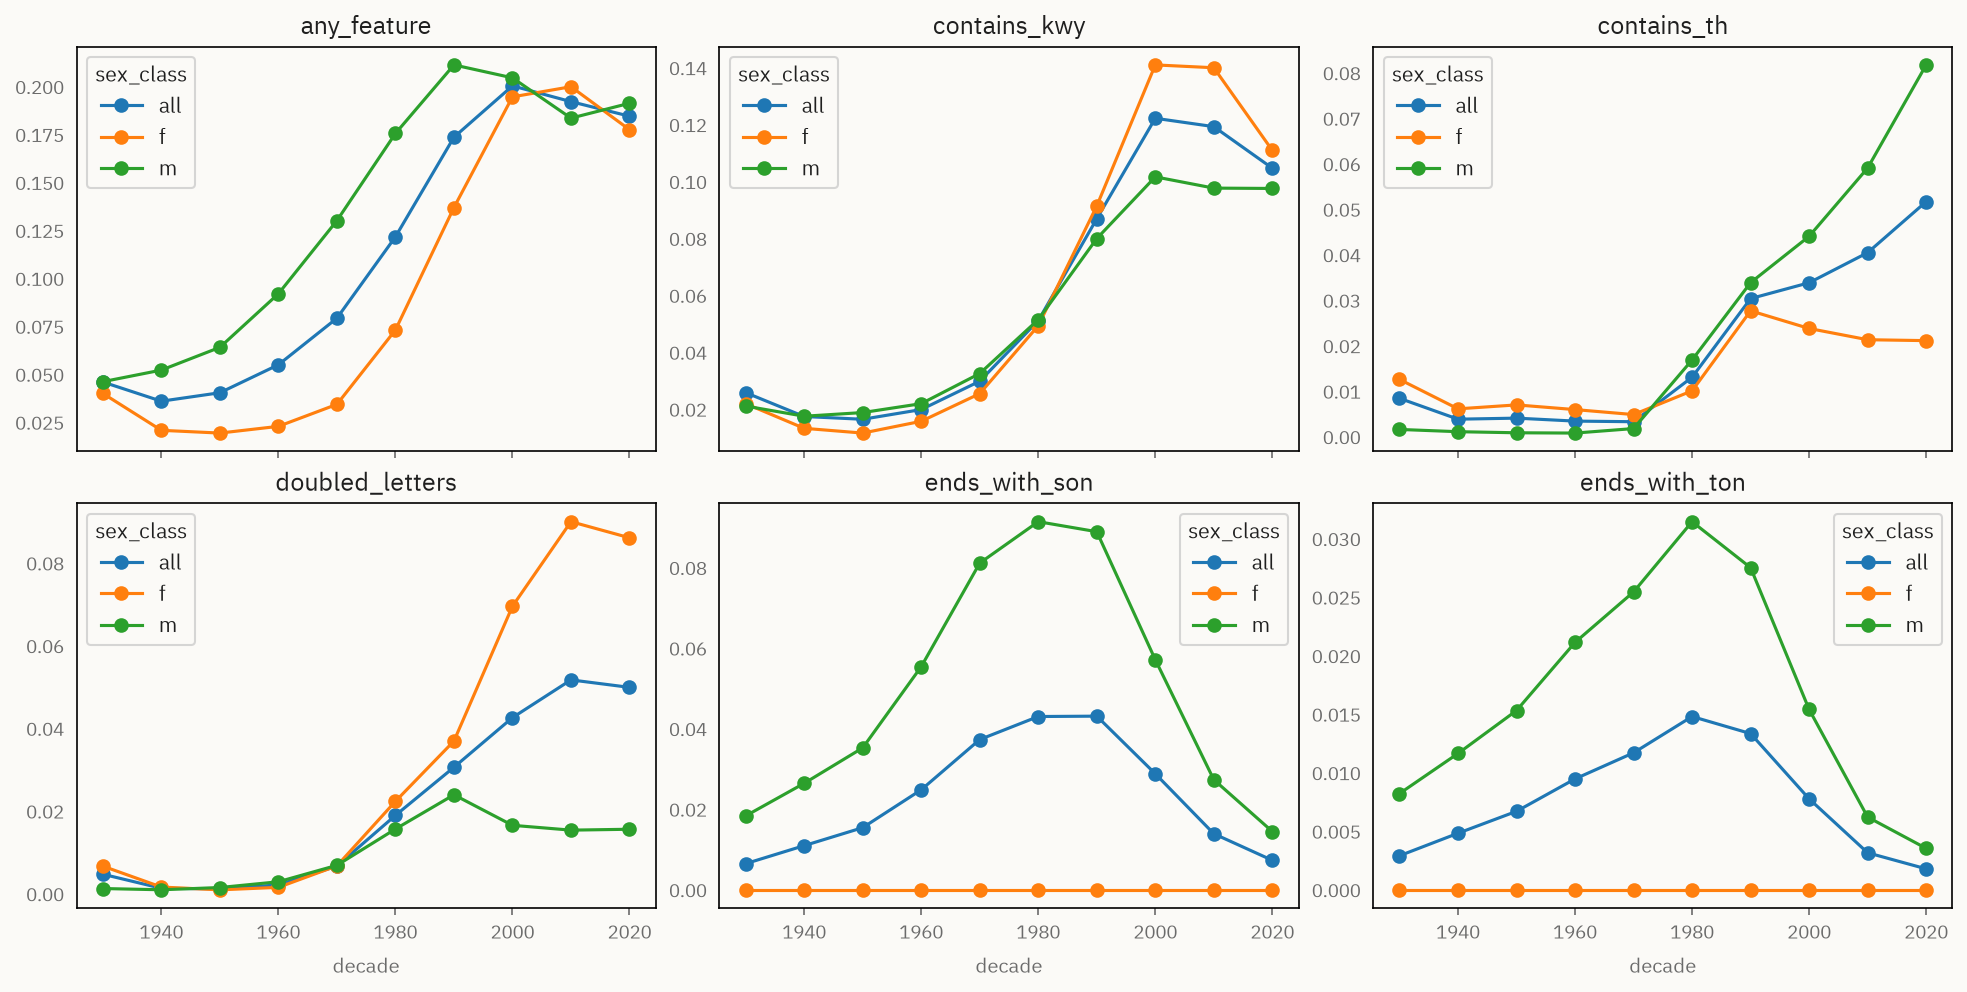

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, layout="constrained")
for ax, (pattern, rows) in zip(axes.flat, spelling.groupby("pattern"), strict=True):
    rows.pivot(index="decade", columns="sex_class", values="share").plot(
        ax=ax, marker="o", title=pattern
    )
plt.show()

The share of listed people whose name matches at least one pattern rises from 3.6% in 1940 to 20.0% in 2000 and is 19.2% in 2010 and 18.5% in 2020. `kwy` follows the same path, from 1.7% in 1940 to 12.2% in 2000. The `son` and `ton` endings rise and then fall: `son_ending` peaks at 4.3% in 1980 and 1990 and is 0.7% in 2020, and `ton_ending` peaks at 1.5% in 1980. `th` and `double_consonant` are both higher in 1930 than in the 1940s to 1960s, then rise to between 4% and 5.2% in 2010 and 2020.

By sex class, the rise is earlier among `m` names: `any` covers 13.0% of the listed people with `m` names in 1970, against 3.4% with `f` names, and the two classes are close from 2000 on (20.5% and 19.5%). `kwy` is more common among `f` names from 1990. The `son` and `ton` endings belong to `m` names: among them, `son_ending` reaches 9.1% in 1980 and `ton_ending` 3.1%, while both stay below 0.01% among `f` names. `double_consonant` reaches 9.0% of the `f` listed people in 2010, and `th` 8.2% of the `m` listed people in 2020.

In the oldest labels, `th` comes mostly from women's names (class `f`) such as `therezinha` and `thereza`; since the 1980s it comes mostly from men's names (class `m`).

After 1990 the `son` and `ton` endings part from `kwy`: `kwy` stays near its peak (12.2% of all listed people in 2000, 10.5% in 2020), while `son_ending` falls from 4.3% in 1990 to 0.7% in 2020 and `ton_ending` from 1.3% to 0.2%.

## 8. Life cycles of names

### 8.1 Eligibility

A name enters the analysis if it accounts for at least 1 in 2,000 listed people in any decade label. Shares use all listed people of the decade, across sex classes.

In [29]:
eligible_shares = shares_by_name[
    shares_by_name.max(axis="columns") >= LIFE_CYCLE_MIN_SHARE
]

### 8.2 Features

Use the base-10 logarithm of a name's share in each decade. For an absent decade, use $10^{-6}$ as a small positive proxy. This proxy is below the disclosure share in the oldest and youngest labels, but the threshold of 20 bearers divided by the listed population falls below it from 1960 to 2010. Observed shares are kept even when they fall below the proxy. Centre and scale each name's ten log shares using its own mean and sample standard deviation, so the fit compares shapes.

In [30]:
log_shares = np.log10(
    eligible_shares.mask(eligible_shares.eq(0), LIFE_CYCLE_ABSENT_SHARE)
)
life_cycle_features = pd.DataFrame(
    zscore(log_shares, axis=1, ddof=1),
    index=log_shares.index,
    columns=log_shares.columns,
)

### 8.3 Model and display scale

Fit scikit-learn k-means with six clusters, 100 initialisations and random state 0. For display, divide each name's share by its own maximum, then take the base-10 log and clip at $-3$. A value of 0 is the peak and $-3$ represents one thousandth of the peak or less, including unlisted decades.

In [31]:
relative_shares = np.log10(
    eligible_shares.div(eligible_shares.max(axis="columns"), axis="index").clip(
        lower=DISPLAY_FLOOR
    )
)

### 8.4 Identifying and ordering the groups

Compute each group's median on the display scale. The comeback score adds the group's median in 1930 and its median in 2020, each measured above the lowest median between 1960 and 1990 inclusive. Put the group with the greatest score last. Order the others by the decade of their median's maximum, taking the first decade if the maximum ties. Ties between groups in that ordering follow the model's label order.

In [32]:
class LifeCycleFit(NamedTuple):
    """Cluster assignments, group medians and comeback cluster id of one k-means fit."""

    clusters: npt.NDArray[np.int32]
    medians: pd.DataFrame
    comeback: int


def fit_life_cycles(
    features: pd.DataFrame,
    relative: pd.DataFrame,
    *,
    k: int,
    n_init: int,
    seed: int,
    trough_decades: tuple[int, int],
) -> LifeCycleFit:
    """Fit k-means and identify the comeback group by the median's rebound score."""
    with threadpool_limits(limits=1):
        clusters = KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit_predict(
            features
        )
    medians = relative.groupby(clusters).median()
    trough_start, trough_end = trough_decades
    trough = medians.loc[:, trough_start:trough_end].min(axis="columns")
    first_decade, last_decade = medians.columns[0], medians.columns[-1]
    comeback_scores = medians[first_decade] + medians[last_decade] - 2 * trough
    return LifeCycleFit(
        clusters=clusters,
        medians=medians,
        comeback=int(comeback_scores.idxmax()),
    )


main_fit = fit_life_cycles(
    life_cycle_features,
    relative_shares,
    k=LIFE_CYCLE_K,
    n_init=KMEANS_N_INIT,
    seed=KMEANS_SEED,
    trough_decades=TROUGH_DECADES,
)
cluster_ids = main_fit.clusters
median_peaks = main_fit.medians.idxmax(axis="columns").drop(index=main_fit.comeback)
display_order = [*median_peaks.sort_values(kind="stable").index, main_fit.comeback]
display_group = {
    cluster: position for position, cluster in enumerate(display_order, start=1)
}
life_cycles = (
    relative_shares.add_prefix("relative_")
    .assign(group=[display_group[cluster] for cluster in cluster_ids])
    .reset_index()[["name", "group", *(f"relative_{decade}" for decade in decades)]]
)

### 8.5 Robustness

For $k=3$ to $10$, report the silhouette on the standardised features. For $k=5$ to $8$, also compare comeback membership with that of the six-cluster fit. Repeat the six-cluster fit for seeds 0 through 9 using 20 initialisations and compare each comeback group with the seed-0 group from that series. Report the intersection size and Jaccard overlap (intersection divided by union), and record the earliest decade of the median's minimum.

In [33]:
def comeback_overlap(
    relative: pd.DataFrame, fit: LifeCycleFit, reference_members: pd.Index
) -> dict[str, int | float]:
    """Measure membership overlap and locate the trough of the comeback median."""
    members = relative.index[fit.clusters == fit.comeback]
    shared = len(members.intersection(reference_members))
    return {
        "comeback_size": len(members),
        "overlap_count": shared,
        "overlap_jaccard": shared / len(members.union(reference_members)),
        "comeback_trough_decade": int(fit.medians.loc[fit.comeback].idxmin()),
    }


main_members = relative_shares.index[cluster_ids == main_fit.comeback]
robustness: list[dict[str, object]] = []
for k in RESOLUTIONS:
    fit = fit_life_cycles(
        life_cycle_features,
        relative_shares,
        k=k,
        n_init=KMEANS_N_INIT,
        seed=KMEANS_SEED,
        trough_decades=TROUGH_DECADES,
    )
    row: dict[str, object] = {
        "comparison": "resolution",
        "k": k,
        "seed": KMEANS_SEED,
        "n_init": KMEANS_N_INIT,
        "silhouette": silhouette_score(life_cycle_features, fit.clusters),
    }
    if k in OVERLAP_RESOLUTIONS:
        row.update(comeback_overlap(relative_shares, fit, main_members))
    robustness.append(row)

seed_zero_fit = fit_life_cycles(
    life_cycle_features,
    relative_shares,
    k=LIFE_CYCLE_K,
    n_init=SEED_RUN_N_INIT,
    seed=KMEANS_SEED,
    trough_decades=TROUGH_DECADES,
)
seed_zero_members = relative_shares.index[
    seed_zero_fit.clusters == seed_zero_fit.comeback
]
for seed in SEED_RUNS:
    fit = fit_life_cycles(
        life_cycle_features,
        relative_shares,
        k=LIFE_CYCLE_K,
        n_init=SEED_RUN_N_INIT,
        seed=seed,
        trough_decades=TROUGH_DECADES,
    )
    robustness.append(
        {
            "comparison": "seed",
            "k": LIFE_CYCLE_K,
            "seed": seed,
            "n_init": SEED_RUN_N_INIT,
            **comeback_overlap(relative_shares, fit, seed_zero_members),
        }
    )

life_cycle_robustness = pd.DataFrame(robustness).astype(
    {
        "comeback_size": "Int64",
        "overlap_count": "Int64",
        "comeback_trough_decade": "Int64",
    }
)
display(life_cycle_robustness)

,comparison,k,seed,n_init,silhouette,comeback_size,overlap_count,overlap_jaccard,comeback_trough_decade
0,resolution,3,0,100,0.495982,<NA>,<NA>,NaN,<NA>
1,resolution,4,0,100,0.446497,<NA>,<NA>,NaN,<NA>
2,resolution,5,0,100,0.435969,75,56,0.736842,1970
3,resolution,6,0,100,0.411586,57,57,1.000000,1970
4,resolution,7,0,100,0.389753,34,27,0.421875,1990
5,resolution,8,0,100,0.383326,65,37,0.435294,1970
6,resolution,9,0,100,0.323973,<NA>,<NA>,NaN,<NA>
7,resolution,10,0,100,0.309848,<NA>,<NA>,NaN,<NA>
8,seed,6,0,20,NaN,57,57,1.000000,1970
9,seed,6,1,20,NaN,57,57,1.000000,1970


In [34]:
comeback_relative = relative_shares.loc[main_members]
trough_start, trough_end = TROUGH_DECADES
member_troughs = comeback_relative.loc[:, trough_start:trough_end].min(axis="columns")
above_at_ends = (comeback_relative[FIRST_DECADE] > member_troughs) & (
    comeback_relative[LAST_DECADE] > member_troughs
)
failing_comebacks = comeback_relative.index[~above_at_ends].tolist()
print(
    f"{above_at_ends.sum()} of {len(comeback_relative)} comeback names exceed "
    f"their {trough_start}-{trough_end} minimum at both ends; "
    f"failing: {', '.join(failing_comebacks)}"
)

54 of 57 comeback names exceed their 1960-1990 minimum at both ends; failing: eloisa, hellena, noa


The silhouette does not single out six groups. Trajectories form a continuum by peak decade, and six groups give one resolution for displaying it. A comeback group separates at every resolution from five to eight. In the ten seed runs, nine return the same set of names as seed 0, while the other run keeps all of that set and adds eight names.

## 9. Results

The results tables, written as CSV with a header row and floats at full precision (pandas writes the shortest representation that reads back as the same number). The figures and the independent audit read them from `results/`.

In [35]:
results = {
    "concentration_by_decade.csv": concentration_by_decade,
    "concentration_common_cutoff.csv": concentration_common_cutoff,
    "concentration_without_top_names.csv": concentration_without_top,
    "concentration_with_unlisted.csv": concentration_with_unlisted,
    "concentration_by_sex_class.csv": concentration_by_class,
    "coverage_by_decade.csv": coverage,
    "distinctive_names.csv": distinctive,
    "distinctive_floor_check.csv": distinctive_floor_check,
    "distinctive_reference_check.csv": distinctive_reference_check,
    "leading_names_by_decade.csv": leading_shares,
    "leading_names_by_sex_class.csv": leading_names_by_class,
    "spelling_by_decade.csv": spelling,
    "spelling_contributors.csv": spelling_contributors,
    "spelling_threshold_check.csv": spelling_threshold_check,
    "sex_class_composition.csv": sex_class_composition,
    "top_names_by_sex_class.csv": top_names_by_class,
    "peak_distinctive_names.csv": peak_distinctive_names,
    "life_cycles.csv": life_cycles,
    "life_cycle_robustness.csv": life_cycle_robustness,
}
for file_name, table in results.items():
    table.to_csv(RESULTS_DIR / file_name, index=False, encoding="utf-8")
    print(f"{file_name}: {len(table)} rows, columns {', '.join(table.columns)}")

concentration_by_decade.csv: 20 rows, columns decade, subset, listed_people, listed_names, top1_name, top1_share, top10_share, top100_share, n50, hill_q1, hill_q2
concentration_common_cutoff.csv: 10 rows, columns decade, cutoff, names_kept, share_kept, hill_q1, hill_q2
concentration_without_top_names.csv: 10 rows, columns decade, first_kept_name, listed_people, listed_names, n50, hill_q1, hill_q2
concentration_with_unlisted.csv: 14 rows, columns decade, unlisted_as, unlisted_people, hill_q1, hill_q2
concentration_by_sex_class.csv: 20 rows, columns decade, sex_class, listed_people, listed_names, top1_name, top1_share, top10_share, n50, hill_q2
coverage_by_decade.csv: 10 rows, columns decade, listed_people, census_people_plain, coverage_plain
distinctive_names.csv: 200 rows, columns decade, name, bearers, share_in_decade, share_elsewhere, log_ratio, rank
distinctive_floor_check.csv: 150 rows, columns min_share, decade, rank, name, log_ratio
distinctive_reference_check.csv: 400 rows, colu

## 10. Figures

The four figures of the post, each drawn in Brazilian Portuguese and in English from the results tables in `results/` and the committed processed tables. They are saved to `figures/` as 1080 × 1350 PNGs. All displayed names use `DISPLAY_NAMES`; the tables retain the IBGE spellings.

In [36]:
CURVE_POINTS = 400
SPELLING_POINTS = 600

decade_positions = np.arange(len(decades))
curve_grid = np.linspace(decade_positions[0], decade_positions[-1], CURVE_POINTS)
spelling_grid = np.linspace(decade_positions[0], decade_positions[-1], SPELLING_POINTS)
sex_cutoff = f"{SEX_CLASS_THRESHOLD:.0%}"


def smooth(values: pd.Series | npt.NDArray[np.float64]) -> npt.NDArray[np.float64]:
    """Interpolate one value per decade onto ``curve_grid`` with PCHIP."""
    return np.asarray(
        PchipInterpolator(decade_positions, np.asarray(values, dtype=float))(
            curve_grid
        ),
        dtype=float,
    )


top_names_for_figure = top_names_by_class.sort_values(
    ["decade", "sex_class", "rank"], ignore_index=True
)
peak_names_for_figure = peak_distinctive_names.sort_values(
    ["decade", "rank"], ignore_index=True
)
cycles_for_figure = life_cycles.sort_values("name").set_index("name")
robustness_for_figure = life_cycle_robustness.sort_values(
    ["comparison", "k", "seed"], ignore_index=True
)
spelling_for_figure = spelling.sort_values(
    ["decade", "pattern", "sex_class"], ignore_index=True
)

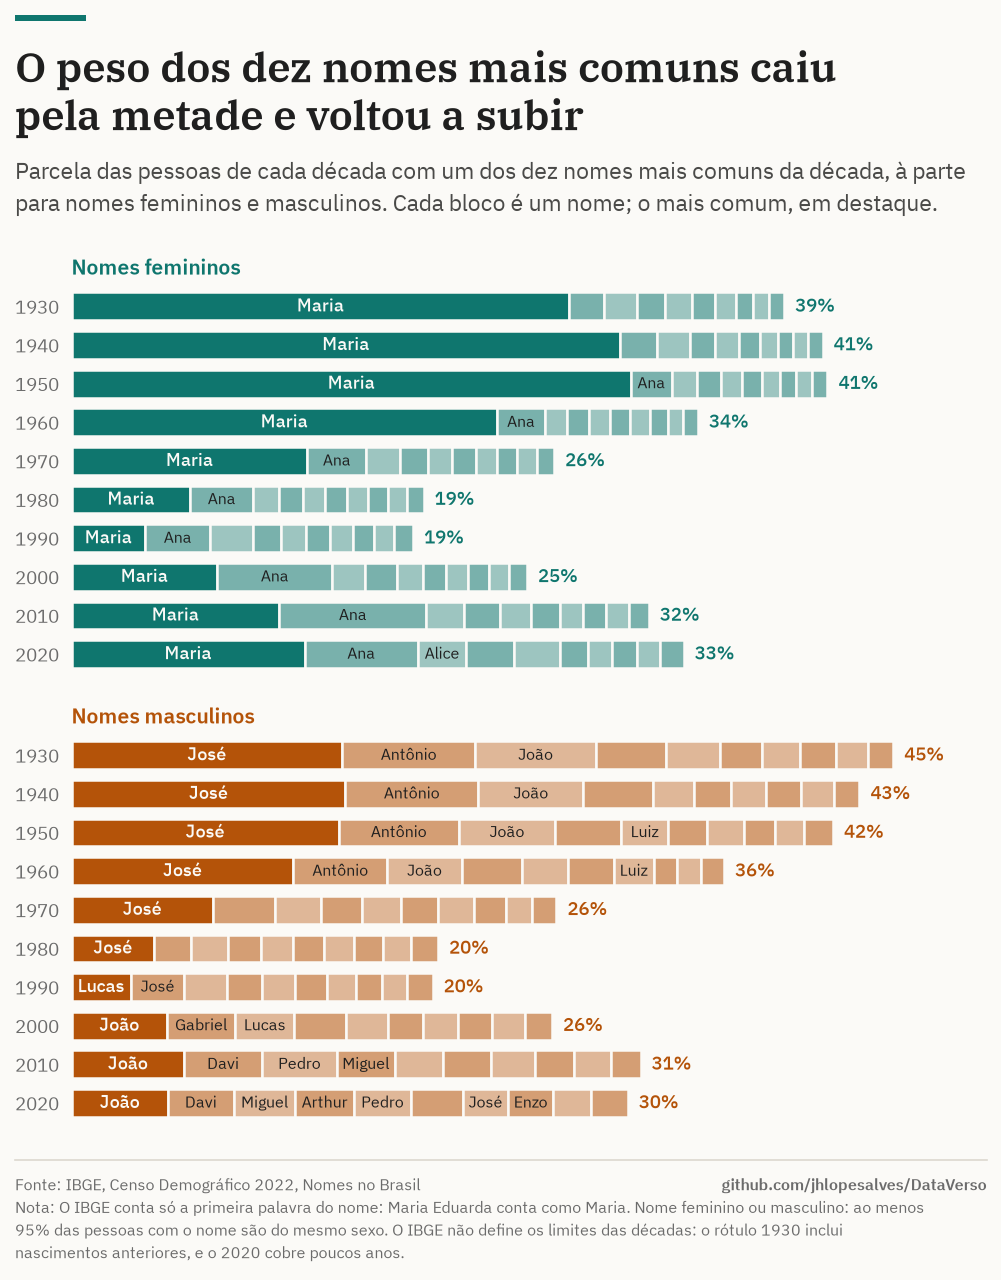

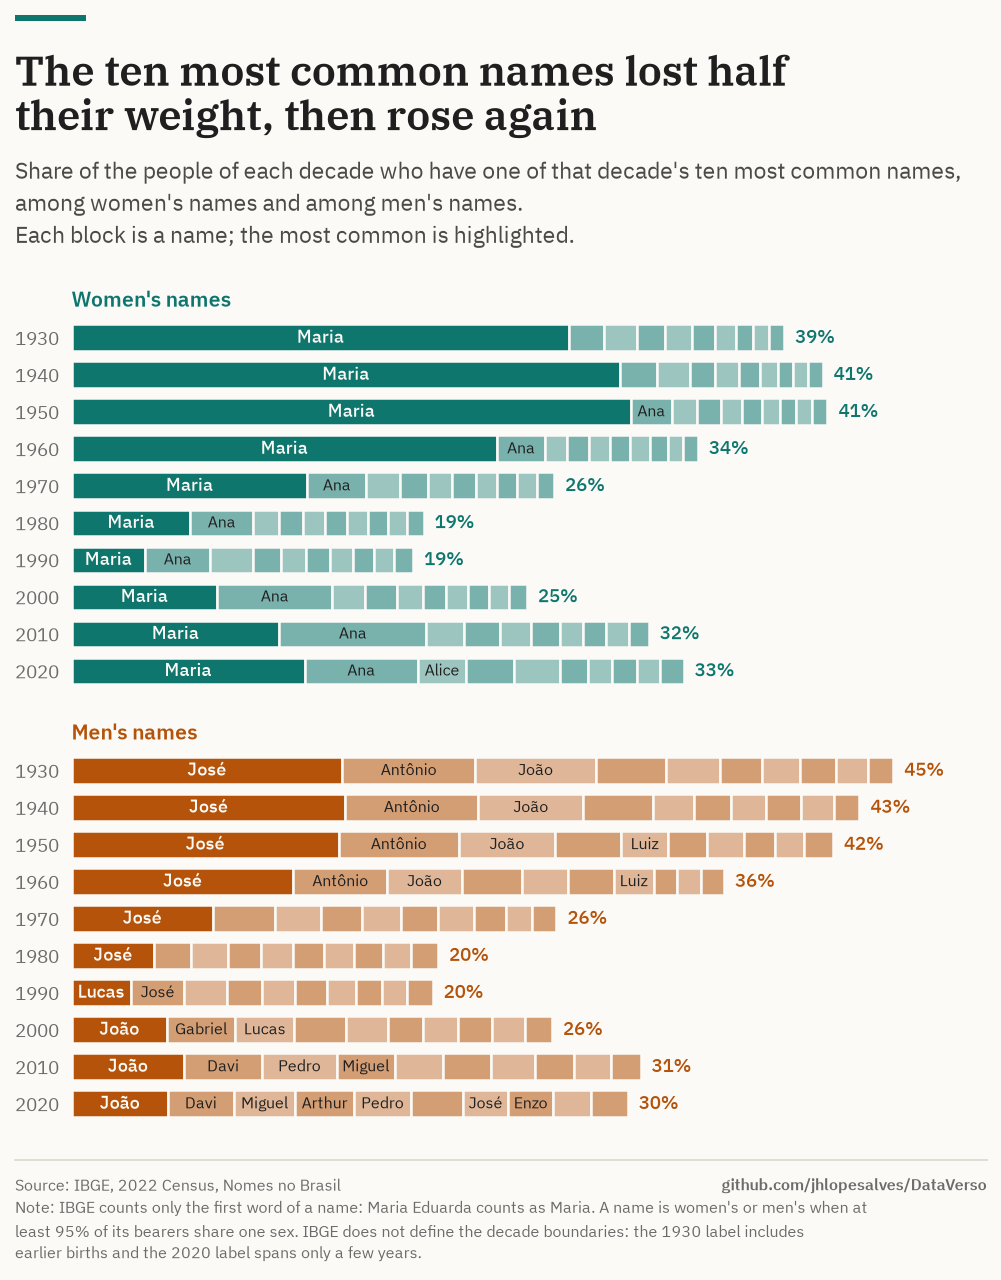

In [37]:
# Figure 1: the ten most common names of each decade and sex class
LEADING_CLEARANCE_PT = 4
SECONDARY_CLEARANCE_PX = 10

top_ten_shares = top_names_for_figure.groupby(["decade", "sex_class"])[
    "share_within_class"
].sum()
x_limit = float(np.ceil(top_ten_shares.max() * 10) / 10)

top_names_text = {
    "pt": {
        "title": "O peso dos dez nomes mais comuns caiu\npela metade e voltou a subir",
        "subtitle": (
            "Parcela das pessoas de cada década com um dos dez nomes mais comuns da década, à parte\n"
            "para nomes femininos e masculinos. Cada bloco é um nome; o mais comum, em destaque."
        ),
        "panels": {"f": "Nomes femininos", "m": "Nomes masculinos"},
        "note": (
            "O IBGE conta só a primeira palavra do nome: Maria Eduarda conta como Maria. Nome feminino ou masculino: ao menos\n"
            f"{sex_cutoff} das pessoas com o nome são do mesmo sexo. O IBGE não define os limites das décadas: o rótulo {decades[0]} inclui\n"
            f"nascimentos anteriores, e o {decades[-1]} cobre poucos anos."
        ),
    },
    "en": {
        "title": "The ten most common names lost half\ntheir weight, then rose again",
        "subtitle": (
            "Share of the people of each decade who have one of that decade's ten most common names,\n"
            "among women's names and among men's names.\n"
            "Each block is a name; the most common is highlighted."
        ),
        "panels": {"f": "Women's names", "m": "Men's names"},
        "note": (
            "IBGE counts only the first word of a name: Maria Eduarda counts as Maria. A name is women's or men's when at\n"
            f"least {sex_cutoff} of its bearers share one sex. IBGE does not define the decade boundaries: the {decades[0]} label includes\n"
            f"earlier births and the {decades[-1]} label spans only a few years."
        ),
    },
}

for lang in LANGUAGES:
    text = top_names_text[lang]
    fig, axes = plt.subplots(2, 1, figsize=SOCIAL_SIZE, sharex=True)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    for ax, sex in zip(axes, ("f", "m"), strict=True):
        ax.set_xlim(0, x_limit)
        ax.set_ylim(len(decades) - 0.5, -0.5)
        ax.set_yticks(decade_positions, decades.astype(str))
        ax.tick_params(axis="y", length=0, labelsize=9)
        ax.tick_params(axis="x", length=0, labelbottom=False)
        ax.spines[:].set_visible(False)
        ax.set_title(
            text["panels"][sex],
            loc="left",
            fontsize=10,
            fontweight="semibold",
            color=CLASS_COLOURS[sex],
            pad=6,
        )

    # Settle the axis range, ticks and titles before measuring any block or label.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax, sex in zip(axes, ("f", "m"), strict=True):
        colour = CLASS_COLOURS[sex]
        group = top_names_for_figure[top_names_for_figure["sex_class"] == sex]
        for row, decade in enumerate(decades):
            left = 0.0
            for item in group[group["decade"] == decade].itertuples(index=False):
                leading = item.rank == 1
                share = item.share_within_class
                face = (
                    colour
                    if leading
                    else tint(colour, 0.55 if item.rank % 2 == 0 else 0.40)
                )
                ax.barh(
                    row,
                    share,
                    left=left,
                    height=0.72,
                    color=face,
                    edgecolor=PAPER,
                    linewidth=1.2,
                )
                x0, x1 = ax.transData.transform([(left, 0), (left + share, 0)])[:, 0]
                clearance = (
                    renderer.points_to_pixels(LEADING_CLEARANCE_PT)
                    if leading
                    else SECONDARY_CLEARANCE_PX
                )
                free_width = x1 - x0 - clearance
                sizes = (8.6, 7.6, 6.8) if leading else (7.8,)
                label = ax.text(
                    left + share / 2,
                    row,
                    display_name(item.name),
                    ha="center",
                    va="center",
                    fontweight="medium" if leading else "regular",
                    color=PAPER if leading else INK,
                )
                fits = False
                for size in sizes:
                    label.set_fontsize(size)
                    if label.get_window_extent(renderer).width <= free_width:
                        fits = True
                        break
                if not fits:
                    label.remove()
                left += share
            ax.text(
                left + 0.006,
                row,
                f"{top_ten_shares.loc[decade, sex]:.0%}",
                va="center",
                fontsize=9,
                color=colour,
                fontweight="medium",
            )
    fig.savefig(FIGURES_DIR / f"01_top_names_{lang}.png")
    plt.show()

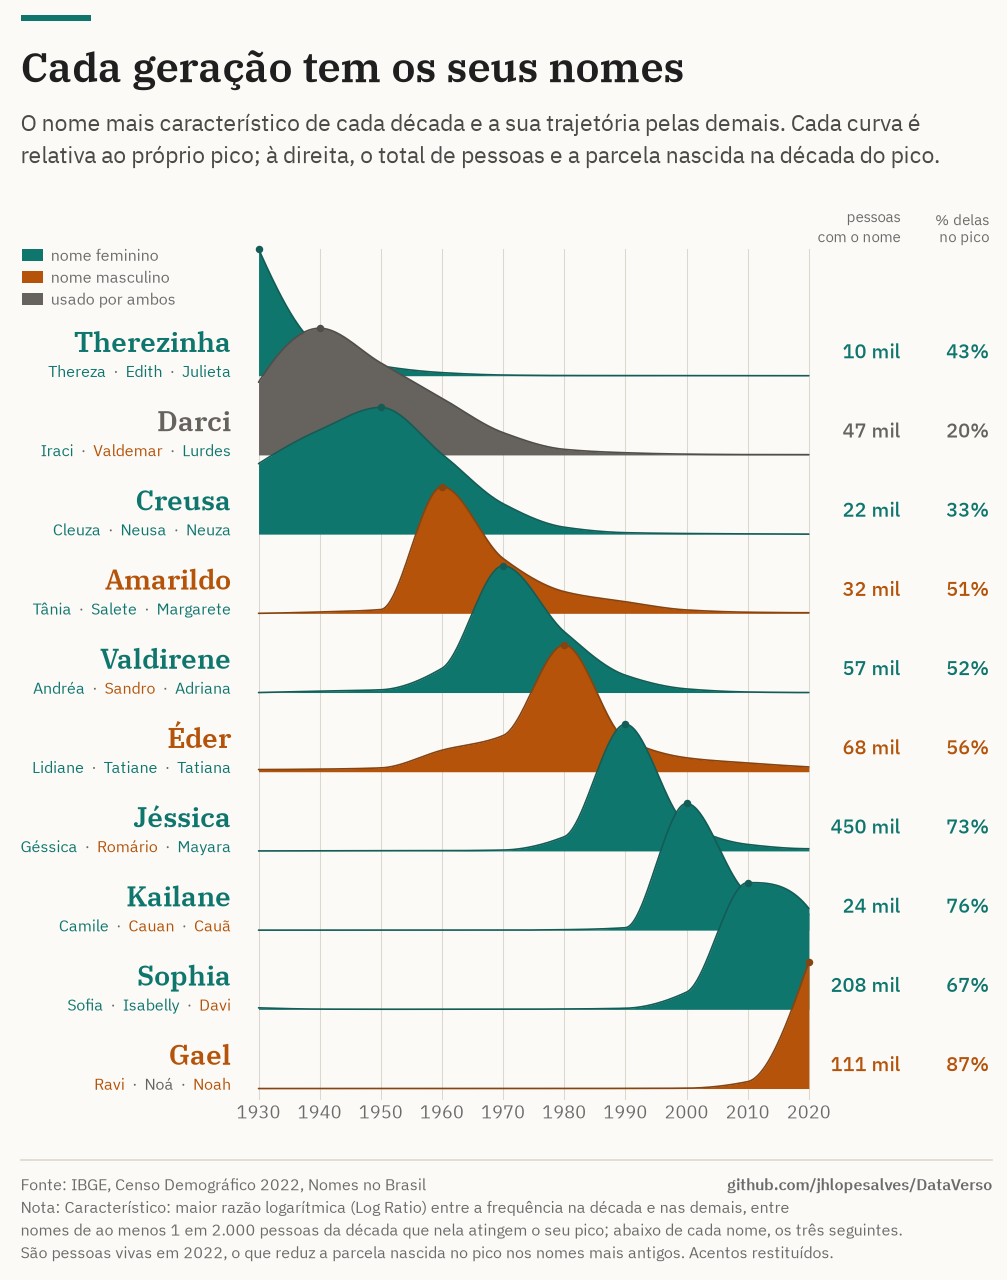

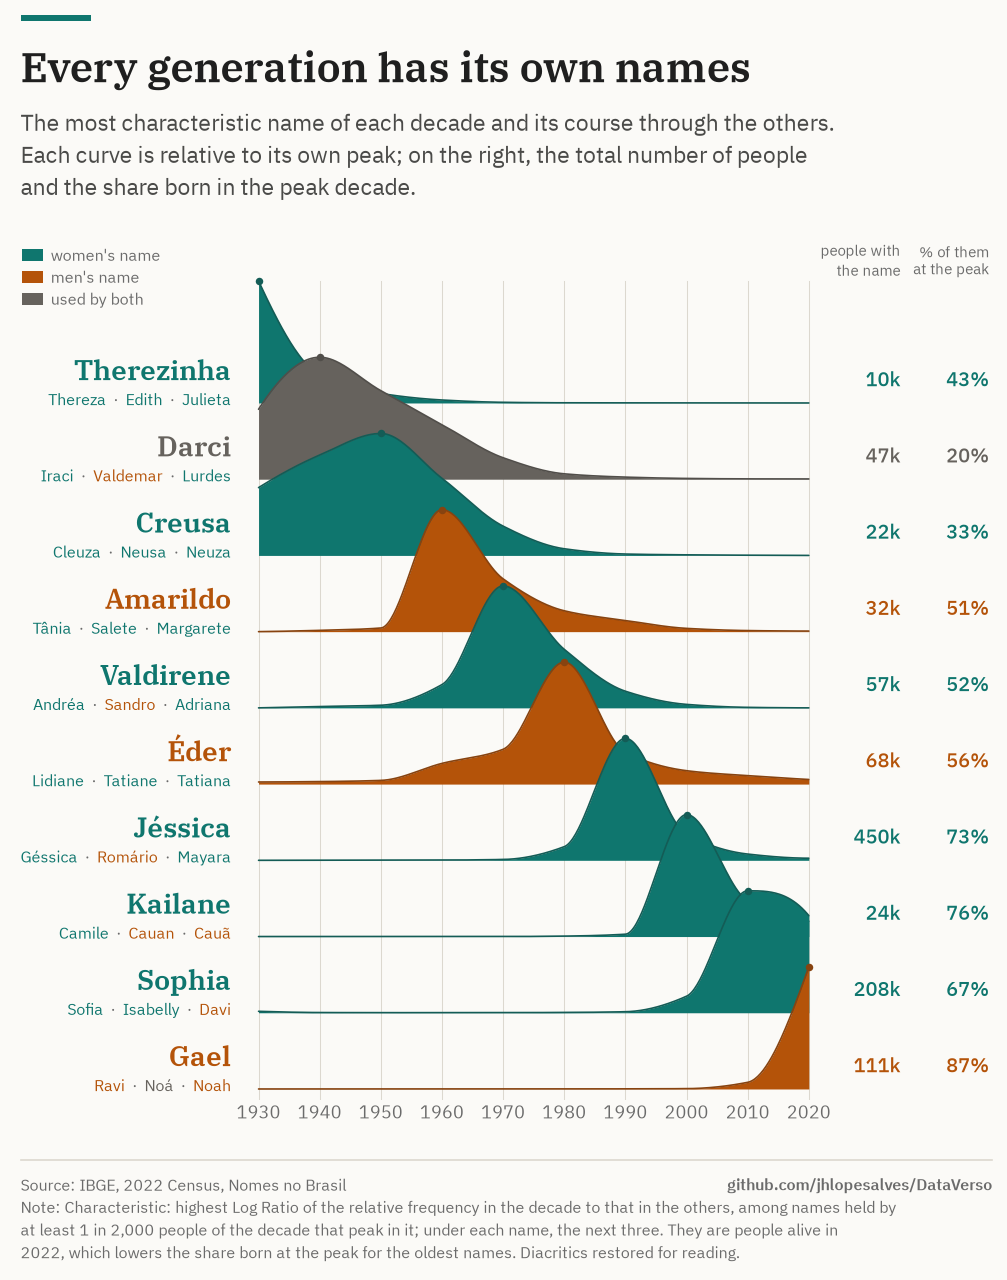

In [38]:
# Figure 2: the leading characteristic name of each decade and its three runners-up
minimum_bearers = round(1 / DISTINCTIVE_MIN_SHARE)
generation_text = {
    "pt": {
        "title": "Cada geração tem os seus nomes",
        "subtitle": (
            "O nome mais característico de cada década e a sua trajetória pelas demais. Cada curva é\n"
            "relativa ao próprio pico; à direita, o total de pessoas e a parcela nascida na década do pico."
        ),
        "note": (
            "Característico: maior razão logarítmica (Log Ratio) entre a frequência na década e nas demais, entre\n"
            f"nomes de ao menos 1 em {format_number(minimum_bearers, 'pt', 0)} pessoas da década que nela atingem o seu pico; abaixo de cada nome, os três seguintes.\n"
            f"São pessoas vivas em {REFERENCE_YEAR}, o que reduz a parcela nascida no pico nos nomes mais antigos. Acentos restituídos."
        ),
        "columns": ("pessoas\ncom o nome", "% delas\nno pico"),
        "legend": ("nome feminino", "nome masculino", "usado por ambos"),
    },
    "en": {
        "title": "Every generation has its own names",
        "subtitle": (
            "The most characteristic name of each decade and its course through the others.\n"
            "Each curve is relative to its own peak; on the right, the total number of people\n"
            "and the share born in the peak decade."
        ),
        "note": (
            "Characteristic: highest Log Ratio of the relative frequency in the decade to that in the others, among names held by\n"
            f"at least 1 in {format_number(minimum_bearers, 'en', 0)} people of the decade that peak in it; under each name, the next three. They are people alive in\n"
            f"{REFERENCE_YEAR}, which lowers the share born at the peak for the oldest names. Diacritics restored for reading."
        ),
        "columns": ("people with\nthe name", "% of them\nat the peak"),
        "legend": ("women's name", "men's name", "used by both"),
    },
}

wave_height = 1.6  # Ridges rise into the row above.
table_columns_x = (10.5, 11.95)
legend_anchor = (0.045, 0.792)
runner_font = FontProperties(family=plt.rcParams["font.family"], size=7.6)
runner_gap = 3.5  # points on either side of each middle dot
for lang in LANGUAGES:
    text = generation_text[lang]
    fig, ax = plt.subplots(figsize=SOCIAL_SIZE)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    renderer = fig.canvas.get_renderer()
    pixels_per_point = renderer.points_to_pixels(1)
    for pos in decade_positions:
        ax.plot(
            [pos, pos],
            [-0.15, decade_positions[-1] + wave_height],
            color=RULE,
            linewidth=0.5,
            zorder=0,
        )
    for row, (_, names) in enumerate(
        peak_names_for_figure.groupby("decade", sort=True)
    ):
        leader = names.iloc[0]
        values = shares_by_name.loc[leader["name"]].to_numpy()
        base = decade_positions[-1] - row
        curve = smooth(values / values.max())
        colour = CLASS_COLOURS[leader["sex_class"]]
        edge = shade(colour, 0.3)
        z = 10 + row * 3  # Later decades sit in front.
        ax.fill_between(
            curve_grid,
            base,
            base + curve * wave_height,
            color=colour,
            linewidth=0,
            zorder=z,
        )
        ax.plot(
            curve_grid,
            base + curve * wave_height,
            color=edge,
            linewidth=0.8,
            zorder=z + 1,
            solid_capstyle="round",
            solid_joinstyle="round",
        )
        peak = int(np.searchsorted(decades, leader["peak_decade"]))
        ax.plot(
            decade_positions[peak],
            base + wave_height,
            "o",
            color=edge,
            markersize=3.6,
            zorder=z + 2,
            markeredgewidth=0,
        )
        thousands = format_number(leader["bearers_national"] / 1000, lang, 0)
        bearers_label = f"{thousands} mil" if lang == "pt" else f"{thousands}k"
        for col_x, value in zip(
            table_columns_x,
            (bearers_label, f"{leader['share_born_at_peak']:.0%}"),
            strict=True,
        ):
            ax.text(
                col_x,
                base + 0.22,
                value,
                ha="right",
                va="baseline",
                fontsize=9.5,
                color=colour,
                fontweight="medium",
                clip_on=False,
            )
        name_anchor = (-0.45, base + 0.30)
        ax.text(
            *name_anchor,
            display_name(leader["name"]),
            ha="right",
            va="baseline",
            fontsize=13.5,
            fontfamily=TITLE_FONT,
            fontweight="semibold",
            color=colour,
        )
        runner_labels = []
        for runner in names.iloc[1:].itertuples(index=False):
            if runner_labels:
                runner_labels.append(("·", MUTED))
            runner_labels.append(
                (display_name(runner.name), CLASS_COLOURS[runner.sex_class])
            )

        # Lay out the pieces from the common right edge, in points independent of the axes.
        offset = 0.0
        for label, label_colour in reversed(runner_labels):
            ax.annotate(
                label,
                xy=name_anchor,
                xytext=(offset, -12),
                textcoords="offset points",
                annotation_clip=False,
                ha="right",
                va="baseline",
                fontproperties=runner_font,
                color=label_colour,
            )
            width, _, _ = renderer.get_text_width_height_descent(
                label, runner_font, ismath=False
            )
            offset -= width / pixels_per_point + runner_gap
    for col_x, header in zip(table_columns_x, text["columns"], strict=True):
        ax.text(
            col_x,
            decade_positions[-1] + wave_height + 0.02,
            header,
            ha="right",
            va="bottom",
            fontsize=7.4,
            color=MUTED,
            linespacing=1.2,
            clip_on=False,
        )
    key = fig.legend(
        handles=[
            Patch(facecolor=colour, edgecolor="none")
            for colour in CLASS_COLOURS.values()
        ],
        labels=text["legend"],
        loc="upper left",
        bbox_to_anchor=legend_anchor,
        ncol=1,
        frameon=False,
        fontsize=7.8,
        handlelength=1.3,
        handleheight=0.8,
        labelspacing=0.35,
        handletextpad=0.5,
        borderaxespad=0.0,
    )
    for label in key.get_texts():
        label.set_color(MUTED)
    ax.set_xticks(decade_positions, decades.astype(str))
    ax.set_xlim(-0.15, 12.0)
    ax.set_ylim(-0.15, decade_positions[-1] + wave_height + 0.12)
    ax.set_yticks([])
    ax.spines[:].set_visible(False)
    ax.tick_params(axis="x", length=0, labelsize=8.5, pad=2)
    fig.savefig(FIGURES_DIR / f"02_generations_{lang}.png")
    plt.show()

Group 1 (Falling since 1930): median peak 1930
Group 2 (Peak in the 1960s): median peak 1960
Group 3 (Peak in the 1970s–80s): median peak 1970
Group 4 (Peak in the 1990s): median peak 1990
Group 5 (Rising): median peak 2020


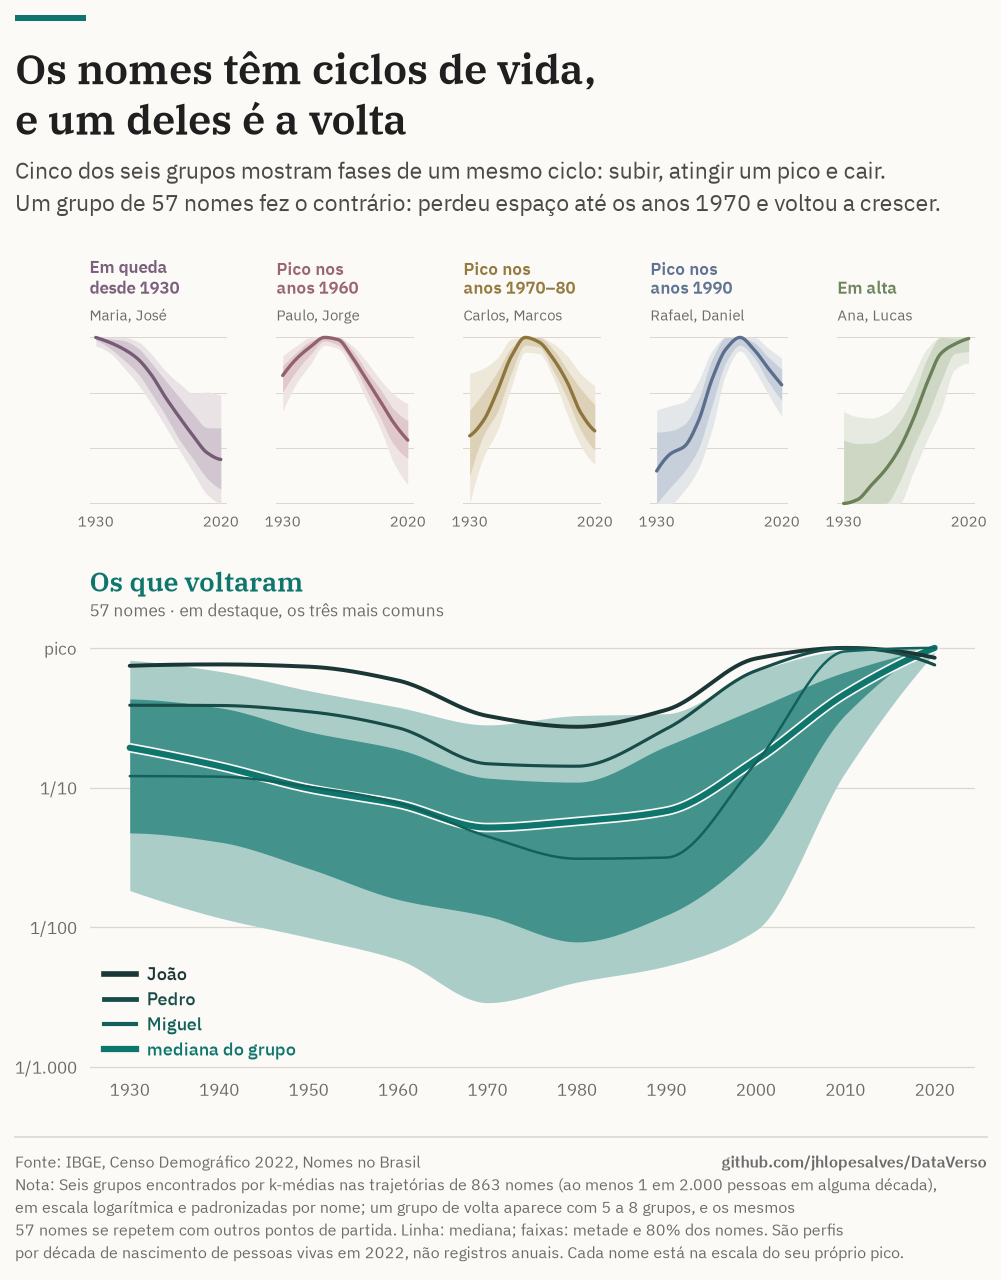

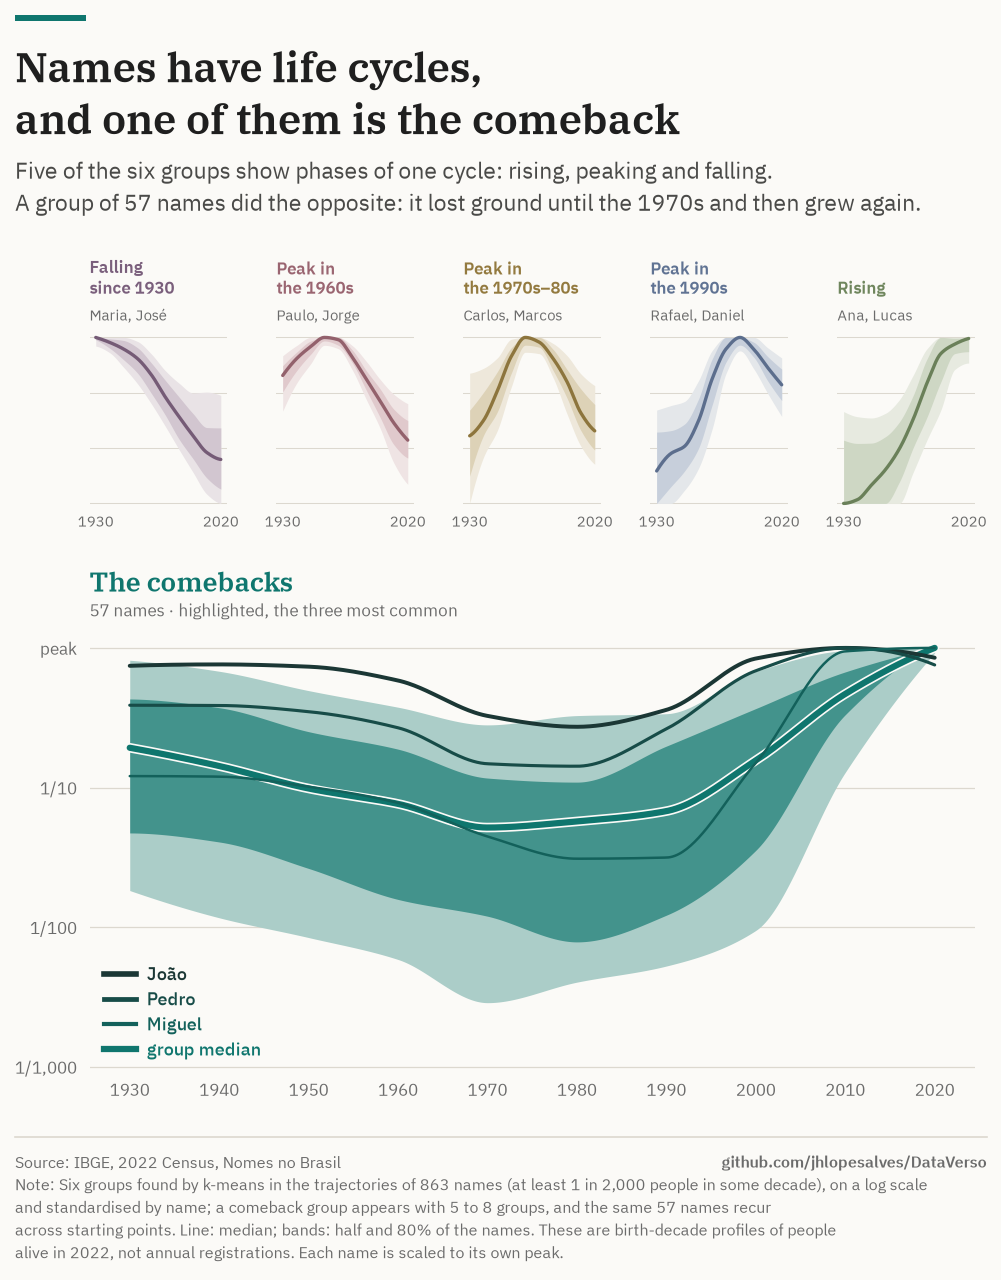

In [39]:
# Figure 3: five context groups and the comeback group, all on the same relative scale
group_ids = cycles_for_figure["group"]
trajectories = cycles_for_figure.drop(columns="group").set_axis(decades, axis="columns")
profiles = trajectories.groupby(group_ids)
group_medians = profiles.median()
context_peaks = group_medians.iloc[:-1].idxmax(axis="columns")
comeback_trough = int(group_medians.loc[LIFE_CYCLE_K].idxmin())
group_size = int(profiles.size().loc[LIFE_CYCLE_K])

resolutions = robustness_for_figure.loc[
    (robustness_for_figure["comparison"] == "resolution")
    & robustness_for_figure["k"].isin(OVERLAP_RESOLUTIONS)
]
resolution_min = int(resolutions["k"].min())
resolution_max = int(resolutions["k"].max())
eligible_size = len(trajectories)
life_cycle_min_bearers = round(1 / LIFE_CYCLE_MIN_SHARE)

life_cycle_text = {
    "pt": {
        "title": "Os nomes têm ciclos de vida,\ne um deles é a volta",
        "subtitle": (
            "Cinco dos seis grupos mostram fases de um mesmo ciclo: subir, atingir um pico e cair.\n"
            f"Um grupo de {group_size} nomes fez o contrário: perdeu espaço até os anos {comeback_trough} e voltou a crescer."
        ),
        "note": (
            f"Seis grupos encontrados por k-médias nas trajetórias de {eligible_size} nomes (ao menos 1 em {format_number(life_cycle_min_bearers, 'pt', 0)} pessoas em alguma década),\n"
            f"em escala logarítmica e padronizadas por nome; um grupo de volta aparece com {resolution_min} a {resolution_max} grupos, e os mesmos\n"
            f"{group_size} nomes se repetem com outros pontos de partida. Linha: mediana; faixas: metade e 80% dos nomes. São perfis\n"
            f"por década de nascimento de pessoas vivas em {REFERENCE_YEAR}, não registros anuais. Cada nome está na escala do seu próprio pico."
        ),
        "small_titles": (
            "Em queda\ndesde 1930",
            "Pico nos\nanos 1960",
            "Pico nos\nanos 1970–80",
            "Pico nos\nanos 1990",
            "Em alta",
        ),
        "big_title": "Os que voltaram",
        "caption": f"{group_size} nomes · em destaque, os três mais comuns",
        "median": "mediana do grupo",
        "ticks": ("pico", "1/10", "1/100", "1/1.000"),
    },
    "en": {
        "title": "Names have life cycles,\nand one of them is the comeback",
        "subtitle": (
            "Five of the six groups show phases of one cycle: rising, peaking and falling.\n"
            f"A group of {group_size} names did the opposite: it lost ground until the {comeback_trough}s and then grew again."
        ),
        "note": (
            f"Six groups found by k-means in the trajectories of {eligible_size} names (at least 1 in {format_number(life_cycle_min_bearers, 'en', 0)} people in some decade), on a log scale\n"
            f"and standardised by name; a comeback group appears with {resolution_min} to {resolution_max} groups, and the same {group_size} names recur\n"
            "across starting points. Line: median; bands: half and 80% of the names. These are birth-decade profiles of people\n"
            f"alive in {REFERENCE_YEAR}, not annual registrations. Each name is scaled to its own peak."
        ),
        "small_titles": (
            "Falling\nsince 1930",
            "Peak in\nthe 1960s",
            "Peak in\nthe 1970s–80s",
            "Peak in\nthe 1990s",
            "Rising",
        ),
        "big_title": "The comebacks",
        "caption": f"{group_size} names · highlighted, the three most common",
        "median": "group median",
        "ticks": ("peak", "1/10", "1/100", "1/1,000"),
    },
}

for title, (group, peak_decade) in zip(
    life_cycle_text["en"]["small_titles"], context_peaks.items(), strict=True
):
    print(f"Group {group} ({title.replace(chr(10), ' ')}): median peak {peak_decade}")

quantiles = profiles.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
# Summing shares across decades gives each decade equal weight when choosing examples.
example_scores = shares_by_name.loc[trajectories.index].sum(axis="columns")
comeback_examples = (
    names_total.loc[
        names_total["name"].isin(group_ids[group_ids == LIFE_CYCLE_K].index), "name"
    ]
    .head(3)
    .tolist()
)
example_colours = [shade(ACCENT, ink) for ink in (0.72, 0.48, 0.24)]
example_widths = (1.9, 1.5, 1.2)
for lang in LANGUAGES:
    text = life_cycle_text[lang]
    fig = plt.figure(figsize=SOCIAL_SIZE)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    grid = fig.add_gridspec(
        2, LIFE_CYCLE_K - 1, height_ratios=[1, 2.5], hspace=0.06, wspace=0.12
    )
    small_axes = [fig.add_subplot(grid[0, i]) for i in range(LIFE_CYCLE_K - 1)]
    big = fig.add_subplot(grid[1, :])

    for group, (ax, colour, title) in enumerate(
        zip(small_axes, GROUP_COLOURS, text["small_titles"], strict=True), start=1
    ):
        q = quantiles.loc[group]
        ax.fill_between(
            curve_grid,
            smooth(q.loc[0.10]),
            smooth(q.loc[0.90]),
            color=tint(colour, 0.16),
            linewidth=0,
        )
        ax.fill_between(
            curve_grid,
            smooth(q.loc[0.25]),
            smooth(q.loc[0.75]),
            color=tint(colour, 0.36),
            linewidth=0,
        )
        ax.plot(
            curve_grid,
            smooth(q.loc[0.50]),
            color=shade(colour, 0.2),
            linewidth=1.6,
            solid_capstyle="round",
        )
        examples = example_scores[group_ids == group].nlargest(2).index
        ax.set_title(
            title,
            loc="left",
            fontsize=8.4,
            fontweight="semibold",
            color=shade(colour, 0.15),
            pad=17,
            linespacing=1.1,
        )
        ax.text(
            0,
            1.03,
            ", ".join(display_name(name) for name in examples),
            transform=ax.transAxes,
            fontsize=7.2,
            color=MUTED,
            va="bottom",
        )
        ax.set_ylim(-3.05, 0.15)
        ax.yaxis.set_major_locator(FixedLocator([0, -1, -2, -3]))
        ax.grid(True, axis="y", color=RULE, linewidth=0.5)
        ax.tick_params(axis="y", labelleft=False)
        ax.set_xticks(
            [decade_positions[0], decade_positions[-1]],
            [str(decades[0]), str(decades[-1])],
        )
        ax.tick_params(axis="both", length=0, labelsize=7.4, labelcolor=MUTED)
        ax.spines[:].set_visible(False)

    q = quantiles.loc[LIFE_CYCLE_K]
    big.fill_between(
        curve_grid,
        smooth(q.loc[0.10]),
        smooth(q.loc[0.90]),
        color=tint(ACCENT, 0.34),
        linewidth=0,
        zorder=1,
    )
    big.fill_between(
        curve_grid,
        smooth(q.loc[0.25]),
        smooth(q.loc[0.75]),
        color=tint(ACCENT, 0.78),
        linewidth=0,
        zorder=2,
    )
    big.plot(
        curve_grid,
        smooth(q.loc[0.50]),
        color=ACCENT,
        linewidth=3.0,
        zorder=4,
        solid_capstyle="round",
        path_effects=[
            patheffects.Stroke(linewidth=4.6, foreground=PAPER),
            patheffects.Normal(),
        ],
    )
    handles = []
    for name, colour, width in zip(
        comeback_examples, example_colours, example_widths, strict=True
    ):
        big.plot(
            curve_grid,
            smooth(trajectories.loc[name]),
            color=colour,
            linewidth=width,
            zorder=5,
            solid_capstyle="round",
        )
        handles.append(Line2D([], [], color=colour, linewidth=width + 0.8))
    handles.append(Line2D([], [], color=ACCENT, linewidth=3.0))
    key = big.legend(
        handles,
        [*(display_name(name) for name in comeback_examples), text["median"]],
        loc="lower left",
        frameon=False,
        fontsize=8.6,
        handlelength=1.8,
        handletextpad=0.6,
        labelspacing=0.4,
        borderaxespad=0.4,
    )
    for label, colour in zip(key.get_texts(), [*example_colours, ACCENT], strict=True):
        label.set_color(colour)
        label.set_fontweight("medium")
    big.set_title(
        text["big_title"],
        loc="left",
        fontsize=13,
        fontweight="semibold",
        color=ACCENT,
        pad=19,
        fontfamily=TITLE_FONT,
    )
    big.text(
        0,
        1.025,
        text["caption"],
        transform=big.transAxes,
        fontsize=8.2,
        color=MUTED,
        va="bottom",
    )
    big.set_ylim(-3.05, 0.12)
    big.set_yticks([0, -1, -2, -3], text["ticks"])
    big.grid(True, axis="y", color=RULE, linewidth=0.6, zorder=0)
    big.set_xticks(decade_positions, decades.astype(str))
    big.tick_params(axis="both", length=0, labelsize=8.4, labelcolor=MUTED)
    big.spines[:].set_visible(False)
    fig.savefig(FIGURES_DIR / f"03_life_cycles_{lang}.png")
    plt.show()

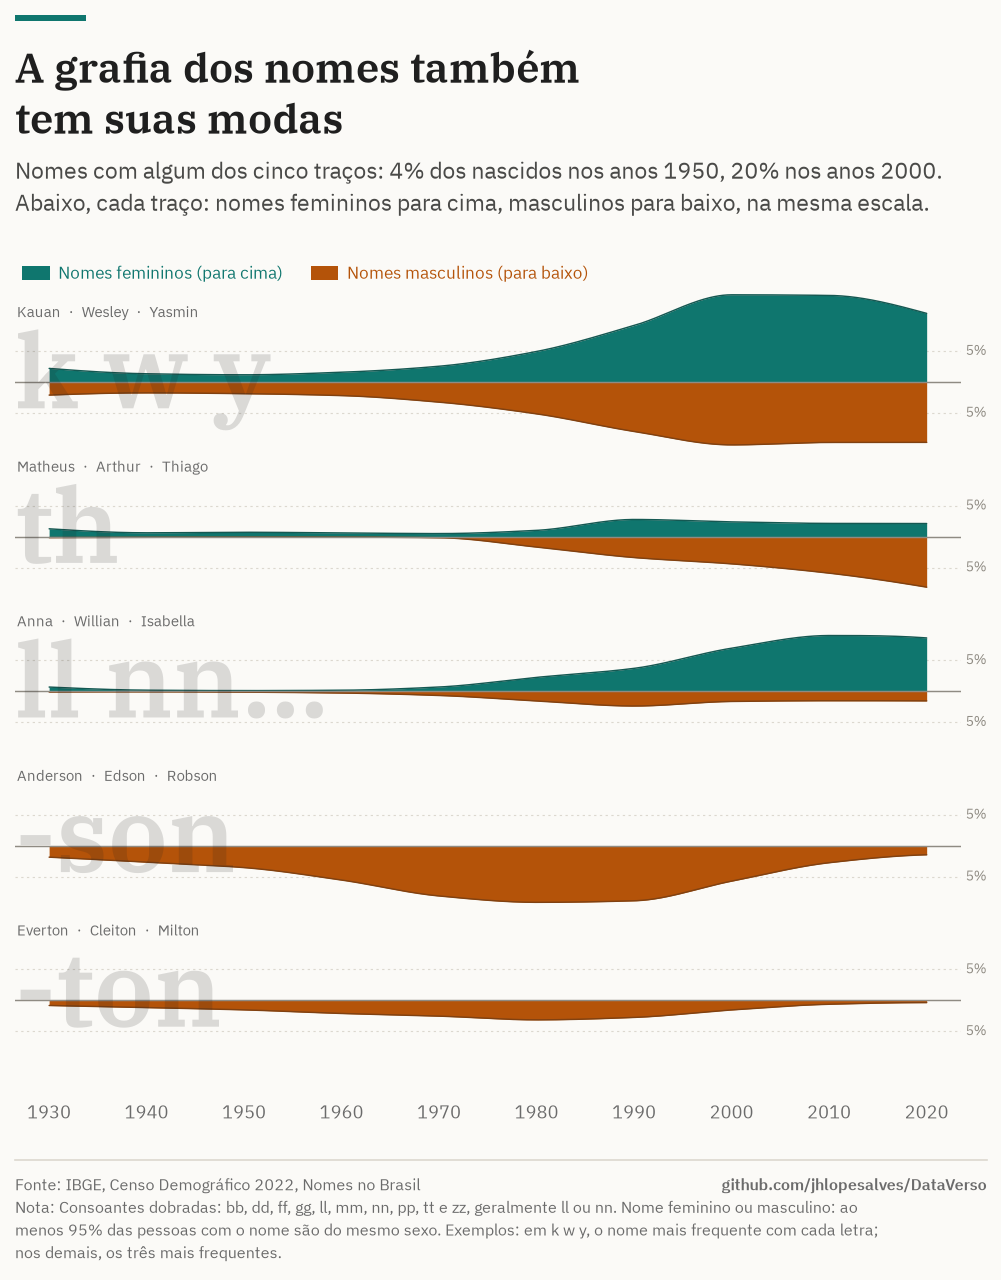

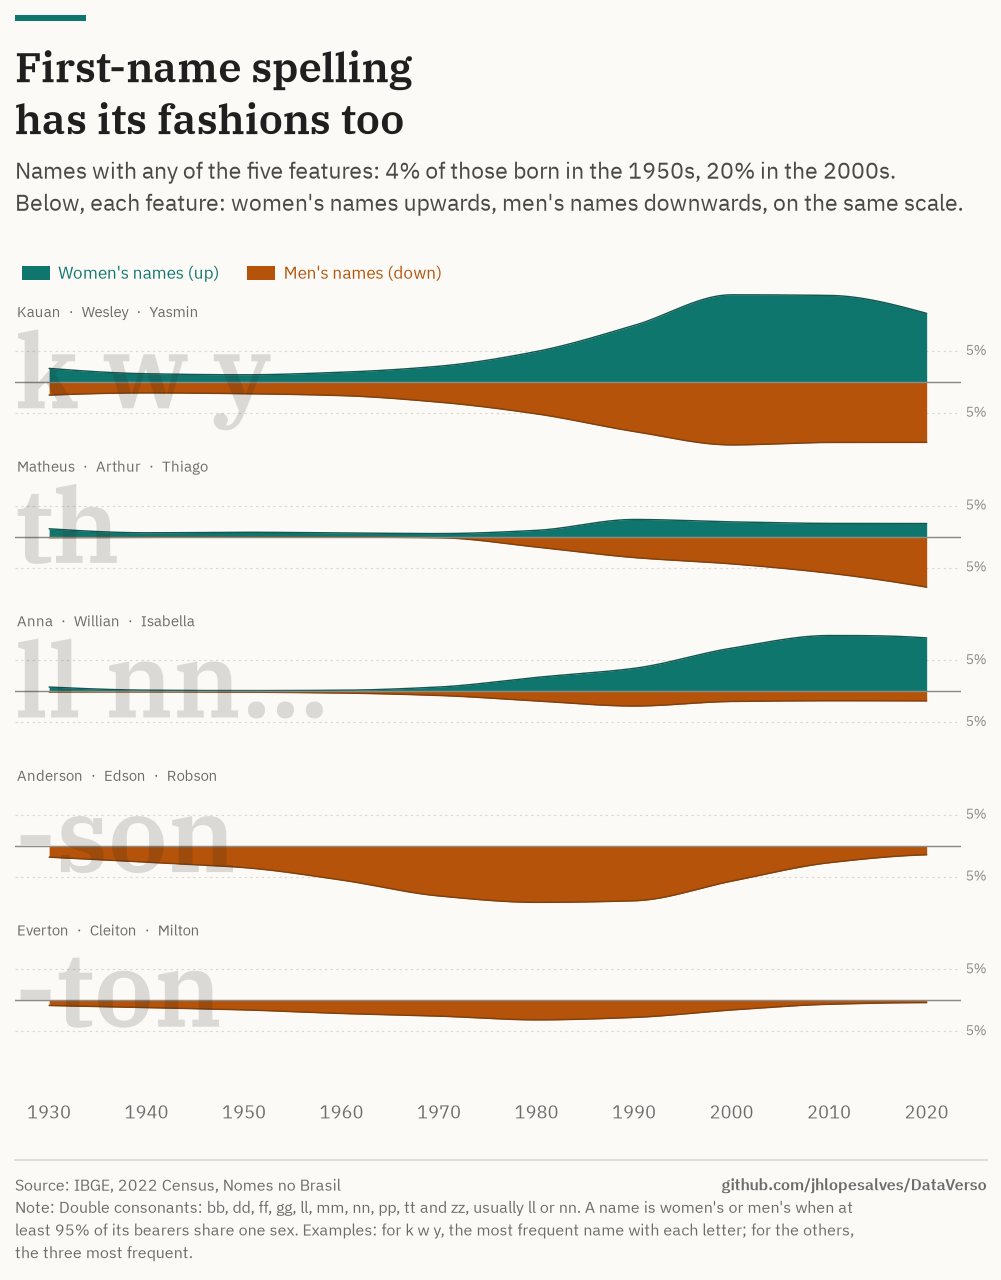

In [40]:
# Figure 4: the spelling patterns on a shared, mirrored scale
spelling_shares = spelling_for_figure.pivot(
    index="decade", columns=["pattern", "sex_class"], values="share"
)
any_share_1950 = f"{spelling_shares.loc[1950, ('any_feature', 'all')]:.0%}"
any_share_2000 = f"{spelling_shares.loc[2000, ('any_feature', 'all')]:.0%}"

double_people = spelling_for_figure.query(
    "pattern == 'doubled_letters' and sex_class == 'all'"
)
ll_nn_people = (
    names_decade[names_decade["name"].str.contains(r"ll|nn")]
    .groupby("decade")["count"]
    .sum()
)
ll_nn_share = ll_nn_people / double_people.set_index("decade")["matching_people"]
mostly_ll_nn = ll_nn_share.loc[1980:].ge(0.95).all()

glyphs = {
    "contains_kwy": "k w y",
    "contains_th": "th",
    "doubled_letters": "ll nn…",
    "ends_with_son": "-son",
    "ends_with_ton": "-ton",
}
examples = {
    "contains_kwy": [
        names_total.loc[
            names_total["name"].str.contains(letter, regex=False), "name"
        ].iloc[0]
        for letter in "kwy"
    ],
    **{
        pattern: names_total.loc[pattern_flags[pattern], "name"].head(3).tolist()
        for pattern in SPELLING_PATTERNS
        if pattern != "contains_kwy"
    },
}

ll_nn_pt = "quase sempre ll ou nn" if mostly_ll_nn else "geralmente ll ou nn"
ll_nn_en = "almost always ll or nn" if mostly_ll_nn else "usually ll or nn"
spelling_text = {
    "pt": {
        "title": "A grafia dos nomes também\ntem suas modas",
        "subtitle": (
            f"Nomes com algum dos cinco traços: {any_share_1950} dos nascidos nos anos 1950, {any_share_2000} nos anos 2000.\n"
            "Abaixo, cada traço: nomes femininos para cima, masculinos para baixo, na mesma escala."
        ),
        "note": (
            f"Consoantes dobradas: bb, dd, ff, gg, ll, mm, nn, pp, tt e zz, {ll_nn_pt}. Nome feminino ou masculino: ao\n"
            f"menos {sex_cutoff} das pessoas com o nome são do mesmo sexo. Exemplos: em k w y, o nome mais frequente com cada letra;\n"
            "nos demais, os três mais frequentes."
        ),
        "legend": ("Nomes femininos (para cima)", "Nomes masculinos (para baixo)"),
    },
    "en": {
        "title": "First-name spelling\nhas its fashions too",
        "subtitle": (
            f"Names with any of the five features: {any_share_1950} of those born in the 1950s, {any_share_2000} in the 2000s.\n"
            "Below, each feature: women's names upwards, men's names downwards, on the same scale."
        ),
        "note": (
            f"Double consonants: bb, dd, ff, gg, ll, mm, nn, pp, tt and zz, {ll_nn_en}. A name is women's or men's when at\n"
            f"least {sex_cutoff} of its bearers share one sex. Examples: for k w y, the most frequent name with each letter; for the others,\n"
            "the three most frequent."
        ),
        "legend": ("Women's names (up)", "Men's names (down)"),
    },
}

x_span = (float(decade_positions[0]) - 0.35, float(decade_positions[-1]) + 0.35)
example_x = float(decade_positions[0]) - 0.33
guide_label_x = float(decade_positions[-1]) + 0.4
max_half_height = 0.6
reference_share = 0.15
scale = max_half_height / reference_share  # 15% spans 0.6 rows in either direction
guide_share = 0.05
n_rows = len(glyphs)
sex_classes = ("f", "m")
sex_colours = [CLASS_COLOURS[sex] for sex in sex_classes]
for lang in LANGUAGES:
    text = spelling_text[lang]
    fig, ax = plt.subplots(figsize=SOCIAL_SIZE)
    frame(
        fig,
        title=text["title"],
        subtitle=text["subtitle"],
        source=SOURCE[lang],
        note=text["note"],
        lang=lang,
    )
    for row, (pattern, glyph) in enumerate(glyphs.items()):
        mid = n_rows - 1 - row
        ax.text(
            x_span[0],
            mid - 0.17,
            glyph,
            ha="left",
            va="baseline",
            fontsize=50,
            fontfamily=TITLE_FONT,
            fontweight="semibold",
            color=INK,
            alpha=0.15,
            zorder=5,
        )
        ax.text(
            example_x,
            mid + 0.42,
            "  ·  ".join(display_name(name) for name in examples[pattern]),
            ha="left",
            va="baseline",
            fontsize=7.4,
            color=MUTED,
            zorder=6,
        )
        for sign, sex in zip((1, -1), sex_classes, strict=True):
            colour = CLASS_COLOURS[sex]
            guide = mid + sign * guide_share * scale
            ax.plot(
                x_span,
                [guide, guide],
                color=RULE,
                linewidth=0.55,
                linestyle=(0, (2, 3)),
                zorder=1,
            )
            ax.text(
                guide_label_x,
                guide,
                f"{guide_share:.0%}",
                ha="left",
                va="center",
                fontsize=6.6,
                color=AXIS,
                clip_on=False,
            )
            values = spelling_shares.loc[decades, (pattern, sex)].to_numpy()
            curve = (
                PchipInterpolator(decade_positions, values)(spelling_grid)
                * scale
                * sign
            )
            ax.fill_between(
                spelling_grid, mid, mid + curve, color=colour, linewidth=0, zorder=3
            )
            if values.any():
                ax.plot(
                    spelling_grid,
                    mid + curve,
                    color=shade(colour, 0.35),
                    linewidth=0.7,
                    zorder=4,
                    solid_capstyle="round",
                )
        ax.plot(x_span, [mid, mid], color=AXIS, linewidth=0.7, zorder=4)

    key = ax.legend(
        handles=[Patch(facecolor=colour, edgecolor="none") for colour in sex_colours],
        labels=text["legend"],
        loc="upper left",
        bbox_to_anchor=(0, 1),
        ncol=2,
        frameon=False,
        fontsize=8.3,
        handlelength=1.6,
        handleheight=0.9,
        columnspacing=1.6,
        borderaxespad=0,
        handletextpad=0.5,
    )
    for label, colour in zip(key.get_texts(), sex_colours, strict=True):
        label.set_color(colour)
    ax.set_xticks(decade_positions, decades.astype(str))
    ax.tick_params(axis="x", length=0, labelsize=8.5, labelcolor=MUTED, pad=4)
    ax.set_yticks([])
    ax.spines[:].set_visible(False)
    ax.set_xlim(*x_span)
    ax.set_ylim(-0.62, n_rows - 1 + 0.8)
    fig.savefig(FIGURES_DIR / f"04_spelling_{lang}.png")
    plt.show()